# 머신러닝 기반 투자정보 질의응답 시스템 개발
### 워런 버핏 투자 데이터 활용

**머신러닝 기말 프로젝트 | 컴퓨터공학과 | 202234561 김은기**

### 프로젝트 개요

본 프로젝트는 투자정보 질의응답 챗봇 개발을 목표로, 사용자의 질문 의도를 자동으로 분류하는 머신러닝 모델을 구현하고 성능을 비교한 프로젝트입니다.

워런 버핏의 공개 투자 원칙과 Berkshire Hathaway의 실제 주식 보유 기록을 활용하였으며, 서로 다른 형태로 제공되는 투자정보를 사용자의 질문에 따라 조회할 수 있는 시스템을 구현하고자 하였습니다.

### 머신러닝 학습 목표

사용자의 질문을 다음 네 가지 유형으로 분류하는 지도학습 문제를 정의하였습니다.

- 투자 원칙 관련 질문
- 특정 분기 보유 현황 질문
- 분기별 보유 변화 질문
- 제공된 자료로 확인할 수 없는 질문

모델은 **단어 TF-IDF + Logistic Regression**을 베이스라인으로, **문자 TF-IDF + Linear SVM**을 비교 모델로 선정하였습니다.

두 모델을 직접 학습하고 검증 및 테스트 데이터에서 성능을 비교하였으며, 테스트셋 Macro-F1 0.80 이상을 정량 목표로 설정하였습니다.

### 데이터 및 서비스 구현

미국 증권거래위원회(SEC)의 2025년 1·2분기 Form 13F 공시자료를 직접 수집하여 Berkshire Hathaway의 보유 종목과 분기별 변화를 분석하였습니다.

또한 공식 주주서한을 바탕으로 워런 버핏의 투자 원칙 14개를 정리하였습니다. 해당 원칙에는 AI 보조 의역이 포함되어 있으며, 원문 대조 검수가 필요한 항목이 남아 있습니다.

학습한 질문 분류 모델은 Gradio 기반 질의응답 프로토타입에 적용하였습니다. 모델이 질문 유형을 판단하면 관련 데이터를 조회하고, 확인된 근거를 바탕으로 답변을 구성하는 방식입니다.

### 프로젝트 범위

이번 프로젝트는 완전한 생성형 AI 챗봇보다는 **질문 분류 모델의 학습과 평가, 실제 서비스 적용 가능성 검증**에 중점을 두었습니다.

답변은 사전에 확보한 자료와 템플릿을 기반으로 구성하며, 확인할 수 없는 투자 판단의 이유는 임의로 생성하지 않도록 설계하였습니다.

본 노트북에서는 데이터 전처리, 모델 학습, 성능 평가 및 질의응답 프로토타입 구현 과정을 확인할 수 있습니다.

## 1. 실행 환경

본 노트북은 Python과 pandas, NumPy, scikit-learn을 사용하여 SEC 공시자료를 처리하고 질문 분류 모델을 학습합니다. 웹 인터페이스에는 Gradio를 사용합니다. 두 분류 모델의 학습 및 추론에 GPU는 필요하지 않습니다.

다음 코드 셀은 실행 환경의 필수 패키지를 확인하고, 설치되지 않은 항목을 설치합니다. 실행에 필요한 패키지 버전은 코드 셀에서 확인할 수 있습니다. 기존 Colab 환경의 설치 상태와 새로운 실행 환경은 다를 수 있으므로, 처음부터 실행할 때 이 셀을 먼저 실행해야 합니다.


In [3]:
import importlib.util, importlib.metadata, subprocess, sys
packages = {"pandas": "pandas>=2.2,<4", "numpy": "numpy>=2.2,<3", "sklearn": "scikit-learn>=1.5,<2", "joblib": "joblib>=1.4,<2", "matplotlib": "matplotlib>=3.8,<4", "gradio": "gradio>=6,<7"}
needed = [requirement for module, requirement in packages.items() if importlib.util.find_spec(module) is None]
if importlib.util.find_spec("gradio") is not None and int(importlib.metadata.version("gradio").split(".")[0]) != 6:
    if "gradio" in sys.modules:
        raise RuntimeError("이미 불러온 Gradio 버전이 다릅니다. 런타임을 다시 시작한 뒤 실행합니다.")
    needed.append("gradio>=6,<7")
if needed:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *needed], check=True)
print("패키지 준비:", needed or "이미 설치됨")


패키지 준비: 이미 설치됨


## 2. 실행 모드 및 원본 데이터 준비

이 노트북은 **SEC Form 13F 원본 데이터의 전처리부터 모델 학습·평가까지 재현**할 수 있도록 구성되어 있습니다. 기본값은 `RUN_MODE = "train"`입니다.

| 실행 모드 | 수행 작업 | 필요한 파일 |
|---|---|---|
| `train` (기본값) | SEC 공시 추출 → 전처리 → 질문 데이터 구성 및 분할 → 두 모델 학습·평가 → 질의응답 기능 실행 | SEC 원본 ZIP 2개 |
| `inference` | 저장된 모델과 근거 데이터를 불러와 질의응답 기능 실행 | 학습 결과 ZIP 또는 저장된 모델 폴더 |

`train` 모드의 입력 파일은 다음 두 개입니다.

- `01mar2025-31may2025_form13f.zip`
- `01jun2025-31aug2025_form13f.zip`

해당 파일이 작업 폴더에 없으면 Colab에서 파일 업로드 창이 표시됩니다. 입력 파일은 변경하지 않으며, 정형화 데이터와 학습 결과는 별도 경로에 저장됩니다.

`inference` 모드는 저장된 모델을 재사용하는 실행 방식입니다. 이 모드에서는 원본 SEC 자료를 다시 처리하거나 분류 모델을 재학습하지 않습니다.

**실행 기록에 관한 안내:** 노트북에 포함된 표와 평가 출력은 Colab에서 수행한 실행 결과입니다. 별도의 새 런타임에서 동일한 과정이 재현되는지는 해당 환경에서 순차 실행하여 확인해야 합니다.


In [4]:
from datetime import datetime
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
import hashlib
import json
import os


def _runtime_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def _runtime_digest(path):
    hasher = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            hasher.update(chunk)
    return hasher.hexdigest()


def verify_saved_model(folder):
    """라이브러리를 import하기 전 파일·학습 완료·해시를 검사합니다."""
    folder = Path(folder).expanduser().resolve()
    if not (folder / "manifest.json").is_file():
        raise FileNotFoundError("학습 모델 manifest.json이 없습니다. 저장한 모델 폴더 또는 결과 ZIP을 지정합니다.")
    manifest = _runtime_json(folder / "manifest.json")
    if manifest.get("training_complete") is not True:
        raise ValueError("학습 완료 가중치가 아닙니다.")
    required = {"retriever.joblib", "knowledge.json", "selection.json", *[name + ".joblib" for name in manifest["models"]]}
    if not required.issubset(manifest["artifact_sha256"]):
        raise ValueError("필수 가중치·근거·선택 파일이 manifest에 없습니다.")
    for name, expected in manifest["artifact_sha256"].items():
        if Path(name).name != name or not (folder / name).is_file() or _runtime_digest(folder / name) != expected:
            raise ValueError("학습 파일 누락 또는 해시 변경: " + name)
    return manifest


def _run_relative(root, value):
    relative = PurePosixPath(value)
    if relative.is_absolute() or ".." in relative.parts or "\\" in value or ":" in value:
        raise ValueError("결과 파일의 상대경로를 확인합니다: " + value)
    target = Path(root).joinpath(*relative.parts).resolve()
    if not target.is_relative_to(Path(root).resolve()):
        raise ValueError("저장 폴더를 벗어나는 경로입니다.")
    return target


def restore_model_archive(archive_path, root):
    archive_path = Path(archive_path).expanduser().resolve()
    if not archive_path.is_file():
        raise FileNotFoundError("학습 결과 ZIP이 없습니다: " + str(archive_path))
    destination = Path(root).resolve() / ".model_cache" / _runtime_digest(archive_path)[:16]
    with ZipFile(archive_path) as archive:
        if archive.testzip() is not None:
            raise ValueError("학습 결과 ZIP의 CRC 오류")
        if "active_run.json" not in archive.namelist():
            raise ValueError("이 ZIP에는 active_run.json이 없습니다. buffett_model_results.zip을 선택합니다.")
        for item in archive.infolist():
            target = _run_relative(destination, item.filename)
            if item.is_dir():
                continue
            data = archive.read(item)
            if target.exists():
                if target.read_bytes() != data:
                    raise FileExistsError("기존 모델 캐시를 보존합니다. 다른 복원 폴더를 지정합니다.")
                continue
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(data)
    return destination


def resolve_saved_run(root, saved_model_dir=None, model_results_zip=None):
    root = Path(root).expanduser().resolve()
    if saved_model_dir:
        folder = Path(saved_model_dir).expanduser()
        folder = (folder if folder.is_absolute() else root / folder).resolve()
        manifest = verify_saved_model(folder)
        return {"model_dir": folder, "report_dir": folder.parent / "reports", "source_root": root,
                "source_kind": "explicit_model_directory", "manifest": manifest}
    if model_results_zip:
        archive = Path(model_results_zip).expanduser()
        archive = archive if archive.is_absolute() else root / archive
        source_root = restore_model_archive(archive, root)
        source_kind = "model_results_zip"
    elif (root / "active_run.json").is_file():
        source_root, source_kind = root, "active_run_json"
    elif (root / "buffett_model_results.zip").is_file():
        source_root = restore_model_archive(root / "buffett_model_results.zip", root)
        source_kind = "model_results_zip"
    else:
        raise FileNotFoundError("저장 모델이 없습니다. active_run.json과 runs/를 준비하거나 MODEL_RESULTS_ZIP 또는 SAVED_MODEL_DIR를 지정합니다. 재학습으로 자동 전환하지 않습니다.")
    active = _runtime_json(source_root / "active_run.json")
    folder = _run_relative(source_root, active["model_dir"])
    manifest = verify_saved_model(folder)
    if active["selected_model"] != manifest["selected_model"]:
        raise ValueError("active_run.json과 가중치 manifest의 선택 모델이 다릅니다.")
    return {"model_dir": folder, "report_dir": _run_relative(source_root, active["report_dir"]),
            "source_root": source_root, "source_kind": source_kind, "manifest": manifest}


def configure_run(root, mode="inference", saved_model_dir=None, model_results_zip=None, raw_dir=None):
    root = Path(root).expanduser().resolve()
    if mode not in {"train", "inference"}:
        raise ValueError("RUN_MODE는 train 또는 inference입니다.")
    if mode == "inference":
        saved = resolve_saved_run(root, saved_model_dir, model_results_zip)
        return {**saved, "root": root, "run_dir": saved["model_dir"].parent, "raw_dir": None, "zip_paths": [],
                "session_output_dir": root / "outputs/inference" / datetime.now().strftime("%Y%m%d_%H%M%S_%f"),
                "mode": mode}
    raw = Path(raw_dir).expanduser().resolve() if raw_dir else root / "raw"
    if not raw_dir:
        previous = root.with_name(root.name.removesuffix("_v2"))
        raw = next((p for p in (root / "raw", root, previous) if len(list(p.glob("*form13f*.zip"))) == 2), raw)
    zip_paths = sorted(raw.glob("*form13f*.zip"))
    if len(zip_paths) != 2:
        raise FileNotFoundError("학습에는 SEC 원본 ZIP 두 개가 필요합니다. RAW_DIR를 확인합니다.")
    run = root / "runs" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    return {"root": root, "run_dir": run, "model_dir": run / "models", "report_dir": run / "reports",
            "raw_dir": raw, "zip_paths": zip_paths, "session_output_dir": run / "reports", "mode": mode,
            "source_root": root, "source_kind": "new_training_run", "manifest": None}

# train: 직접 수집한 SEC 원본으로 전처리·학습·평가 / inference: 저장 모델 시연
RUN_MODE = "train"
ROOT = Path(os.environ.get("BUFFETT_ROOT", Path.cwd())).expanduser().resolve()
SAVED_MODEL_DIR = os.environ.get("BUFFETT_MODEL_DIR") or None
MODEL_RESULTS_ZIP = os.environ.get("BUFFETT_RESULTS_ZIP") or None
RAW_DIR = os.environ.get("BUFFETT_RAW_DIR") or None
AUTO_INSTALL_MODEL_VERSIONS = True
import importlib.metadata, importlib.util, subprocess, sys
try:
    PATHS = configure_run(ROOT, RUN_MODE, SAVED_MODEL_DIR, MODEL_RESULTS_ZIP, RAW_DIR)
except FileNotFoundError as path_error:
    try:
        from google.colab import files as colab_files
    except ImportError:
        raise path_error
    if RUN_MODE == "inference":
        print("이미 학습한 buffett_model_results.zip 하나를 선택합니다. 원본 ZIP은 필요 없습니다.")
        uploaded = colab_files.upload()
        if len(uploaded) != 1:
            raise ValueError("모델 결과 ZIP 하나만 선택합니다.")
        MODEL_RESULTS_ZIP = ROOT / next(iter(uploaded))
    else:
        print("직접 수집한 SEC 13F 원본 ZIP 두 개를 선택합니다.")
        uploaded = colab_files.upload()
        RAW_DIR = ROOT
    del uploaded
    PATHS = configure_run(ROOT, RUN_MODE, SAVED_MODEL_DIR, MODEL_RESULTS_ZIP, RAW_DIR)
RUN_DIR, MODEL_DIR, REPORT_DIR = [PATHS[k] for k in ("run_dir", "model_dir", "report_dir")]
ZIP_PATHS, SESSION_OUTPUT_DIR = PATHS["zip_paths"], PATHS["session_output_dir"]
os.environ["MPLCONFIGDIR"] = str(ROOT / "tmp/matplotlib")
if RUN_MODE == "inference":
    manifest = PATHS["manifest"]
    versions = {"scikit-learn": manifest["sklearn_version"], "numpy": manifest["numpy_version"], "pandas": manifest["pandas_version"], "joblib": manifest["joblib_version"]}
    missing_versions = []
    loaded_conflicts = []
    for package, wanted in versions.items():
        try:
            installed = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            installed = None
        if installed != wanted:
            module = "sklearn" if package == "scikit-learn" else package
            if module in sys.modules:
                loaded_conflicts.append(package)
            missing_versions.append(package + "==" + wanted)
    if missing_versions and AUTO_INSTALL_MODEL_VERSIONS:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing_versions], check=True)
    if loaded_conflicts:
        raise RuntimeError("학습 버전 설치 후 이미 불러온 모듈이 남아 있습니다. 런타임을 다시 시작하고 위에서부터 실행합니다. 재학습은 필요 없습니다.")
    if missing_versions and not AUTO_INSTALL_MODEL_VERSIONS:
        raise RuntimeError("학습 버전을 먼저 설치합니다: " + " ".join(missing_versions))
print("실행 모드:", RUN_MODE)
print("모델 출처:", PATHS["source_kind"])
print("가중치 저장/로드 경로:", MODEL_DIR)
print("학습 보고서(읽기):", REPORT_DIR)
print("이번 시연 로그(별도 저장):", SESSION_OUTPUT_DIR)
print("원본 ZIP:", [p.name for p in ZIP_PATHS])


직접 수집한 SEC 13F 원본 ZIP 두 개를 선택합니다.


Saving 01jun2025-31aug2025_form13f.zip to 01jun2025-31aug2025_form13f.zip
Saving 01mar2025-31may2025_form13f.zip to 01mar2025-31may2025_form13f.zip
실행 모드: train
모델 출처: new_training_run
가중치 저장/로드 경로: /content/runs/20261119_115608_098551/models
학습 보고서(읽기): /content/runs/20261119_115608_098551/reports
이번 시연 로그(별도 저장): /content/runs/20261119_115608_098551/reports
원본 ZIP: ['01jun2025-31aug2025_form13f.zip', '01mar2025-31may2025_form13f.zip']


## 3. 데이터 처리에 사용할 공통 함수

원본 데이터에서 날짜·숫자·문자열 형식을 일관되게 처리하기 위한 함수를 정의했습니다. 공시 고유번호(ACCESSION_NUMBER), 기관 식별번호(CIK), 증권 식별번호(CUSIP)는 숫자로 변환하지 않고 문자열로 유지하여 식별 정보가 손상되지 않도록 했습니다.

분석 범위는 Berkshire Hathaway의 **2025년 3월 31일과 6월 30일 기준 보유 자료**이며, 학습 데이터 분할과 실험의 재현을 위해 난수 시드를 42로 설정했습니다.


In [5]:
from collections import Counter
from datetime import datetime, timezone
from decimal import Decimal
from pathlib import Path
from zipfile import ZipFile
import hashlib
import json
import re
import time
import unicodedata

import joblib
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score

CIK = "0001067983"
PERIODS = ("2025-03-31", "2025-06-30")
LABELS = ["INVESTMENT_PRINCIPLE", "HOLDING_FACT", "HOLDING_CHANGE", "UNSUPPORTED"]
SEC_SCOPE_URL = "https://www.sec.gov/rules-regulations/staff-guidance/frequently-asked-questions-about-form-13f"
SEED = 42


def digest(path):
    hasher = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for part in iter(lambda: stream.read(1024 * 1024), b""):
            hasher.update(part)
    return hasher.hexdigest()


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8", newline="\n")


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def clean(value):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(value))).strip()


def sec_date(value):
    months = {m: i + 1 for i, m in enumerate("JAN FEB MAR APR MAY JUN JUL AUG SEP OCT NOV DEC".split())}
    day, month, year = clean(value).upper().split("-")
    return datetime(int(year), months[month], int(day)).date().isoformat()


def exact_int(value, field):
    text = clean(value).replace(",", "")
    if not re.fullmatch(r"\d+(?:\.0+)?", text):
        raise ValueError(f"{field}: 결측·음수·잘못된 수치 {value!r}")
    return int(Decimal(text))


def zip_member(archive, basename):
    found = [n for n in archive.namelist() if Path(n).name.casefold() == basename.casefold()]
    if len(found) != 1:
        raise ValueError(f"{basename}: ZIP 내부에서 고유하게 찾지 못했습니다: {found}")
    return found[0]


def security_key(row):
    return (row["cusip"], row["title_of_class"], row["amount_type"], row["put_call"] or "")


def short_id(prefix, parts):
    return prefix + hashlib.sha256(json.dumps(parts, ensure_ascii=False).encode()).hexdigest()[:16]


def filing_url(accession):
    return f'https://www.sec.gov/Archives/edgar/data/{int(CIK)}/{accession.replace("-", "")}/{accession}-index.html'



import sklearn
print("실제 버전:", {"Python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__, "joblib": joblib.__version__})


실제 버전: {'Python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'scikit-learn': '1.6.1', 'joblib': '1.6.0'}


## 4. SEC 13F 데이터 정형화

### 원본 데이터와 처리 방법

사용한 자료는 SEC의 분기별 Form 13F 데이터셋입니다. `SUBMISSION`, `COVERPAGE`, `SUMMARYPAGE`, `INFOTABLE`을 공시 고유번호(`ACCESSION_NUMBER`)로 연결하고, CIK와 기관명을 확인하여 Berkshire Hathaway의 기록만 추출했습니다.

주요 전처리 과정은 다음과 같습니다.

1. **기관·기간 필터링:** 전체 기관 공시에서 Berkshire Hathaway와 2025년 1·2분기 기록을 선택합니다.
2. **수정 공시 반영:** `13F-HR/A`의 수정 유형을 확인해 정정(`RESTATEMENT`)과 추가 공개(`NEW HOLDINGS`)를 구분합니다.
3. **형식 및 결측값 정리:** 날짜와 숫자형 필드를 변환하고, 선택적 필드의 공란을 일관되게 처리합니다.
4. **증권별 집계 및 비교:** 동일 증권의 신고 수량을 정리하고 두 분기의 보유 변화 유형을 계산합니다.

원본 ZIP은 변경하지 않고 읽기 전용으로 처리합니다. 파일 내부 폴더 구조가 서로 달라도 필요한 TSV를 찾도록 구현했으며, 대용량 `INFOTABLE`은 청크 단위로 읽습니다. 2025년 공시의 `VALUE`는 원본 메타데이터에 명시된 **미국 달러(USD)** 단위를 따릅니다.

아래 출력에서는 필터링 전후 행 수, 수정 공시 적용 과정, 정형화 사례, 보유 변화 라벨 분포를 확인할 수 있습니다. **13F는 분기 말 보유 현황이므로 보유 수량 변화만으로 실제 거래 시점이나 투자 동기를 단정하지 않습니다.**


In [6]:
def load_sec_archives(zip_paths, output_dir=None):
    """원본은 읽기만 합니다. INFOTABLE을 청크로 순회해 전체 기관을 메모리에 올리지 않습니다."""
    filings, raw, inventories, units = {}, [], [], []
    preprocessing = Counter()
    examples = []
    for path in map(Path, zip_paths):
        if not path.is_file():
            raise FileNotFoundError("SEC 원본 ZIP이 없습니다: " + str(path))
        with ZipFile(path) as archive:
            if archive.testzip() is not None:
                raise ValueError("ZIP CRC 검사 실패: " + path.name)
            members = {n: zip_member(archive, n) for n in ("SUBMISSION.tsv", "COVERPAGE.tsv", "SUMMARYPAGE.tsv", "INFOTABLE.tsv", "FORM13F_metadata.json")}
            metadata = json.loads(archive.read(members["FORM13F_metadata.json"]))
            table = next(t for t in metadata["tables"] if t["url"].upper() == "INFOTABLE.TSV")
            unit = next(c["dc:description"] for c in table["tableSchema"]["columns"] if c["name"] == "VALUE")
            if "nearest dollar" not in unit.lower():
                raise ValueError("2025년 VALUE 단위를 원본 metadata에서 확인하지 못했습니다.")
            units.append({"archive": path.name, "value_definition": unit})
            tables = {}
            for name in ("SUBMISSION.tsv", "COVERPAGE.tsv", "SUMMARYPAGE.tsv"):
                with archive.open(members[name]) as stream:
                    tables[name] = pd.read_csv(stream, sep="\t", dtype=str, keep_default_na=False)
            submission = tables["SUBMISSION.tsv"]
            cover = tables["COVERPAGE.tsv"]
            summary = tables["SUMMARYPAGE.tsv"]
            selected = submission[submission["CIK"].str.lstrip("0").eq(str(int(CIK)))].copy()
            selected = selected[selected["PERIODOFREPORT"].map(sec_date).isin(PERIODS)]
            selected = selected[selected["SUBMISSIONTYPE"].isin(["13F-HR", "13F-HR/A"])]
            joined = selected.merge(cover, on="ACCESSION_NUMBER", validate="one_to_one").merge(summary, on="ACCESSION_NUMBER", validate="one_to_one")
            for row in joined.to_dict("records"):
                name = clean(row["FILINGMANAGER_NAME"])
                if re.sub(r"[^A-Z]", "", name.upper()) != "BERKSHIREHATHAWAYINC":
                    raise ValueError("CIK와 기관명이 일치하지 않습니다: " + name)
                period = sec_date(row["PERIODOFREPORT"])
                if sec_date(row["REPORTCALENDARORQUARTER"]) != period:
                    raise ValueError("보고 기준일과 표지의 날짜가 다릅니다.")
                accession = row["ACCESSION_NUMBER"]
                item = {"source_id": accession, "accession_number": accession, "cik": CIK, "reporting_entity": name,
                        "period_end": period, "filing_date": sec_date(row["FILING_DATE"]), "submission_type": row["SUBMISSIONTYPE"],
                        "amendment_type": clean(row["AMENDMENTTYPE"]).upper(), "amendment_number": int(row["AMENDMENTNO"] or 0),
                        "declared_rows": exact_int(row["TABLEENTRYTOTAL"], "TABLEENTRYTOTAL"), "declared_value_usd": exact_int(row["TABLEVALUETOTAL"], "TABLEVALUETOTAL"),
                        "confidential_omitted": row["ISCONFIDENTIALOMITTED"], "additional_information": row["ADDITIONALINFORMATION"], "source_url": filing_url(accession)}
                if accession in filings and filings[accession] != item:
                    raise ValueError("중복 accession의 공시 내용이 다릅니다.")
                filings[accession] = item
            accessions = set(joined["ACCESSION_NUMBER"])
            total_rows = selected_rows = 0
            with archive.open(members["INFOTABLE.tsv"]) as stream:
                for chunk in pd.read_csv(stream, sep="\t", dtype=str, keep_default_na=False, chunksize=150_000):
                    total_rows += len(chunk)
                    matches = chunk[chunk["ACCESSION_NUMBER"].isin(accessions)]
                    selected_rows += len(matches)
                    raw.extend(matches.to_dict("records"))
            inventories.append({"archive": path.name, "sha256": digest(path), "zip_members": len(archive.namelist()),
                                "submission_rows": len(submission), "cover_rows": len(cover), "infotable_rows": total_rows,
                                "selected_rows": selected_rows, "columns": list(chunk.columns), "member_paths": members})
    if not raw:
        raise ValueError("두 ZIP에서 지정 CIK·보고 기간의 보유 행을 찾지 못했습니다.")
    # 기술적 기본키 중복만 제거합니다. 같은 종목의 서로 다른 운용 주체 행을 삭제하지 않습니다.
    unique = {}
    for row in raw:
        key = (row["ACCESSION_NUMBER"], row["INFOTABLE_SK"])
        if key in unique and unique[key] != row:
            raise ValueError("같은 원본 기본키의 값이 다릅니다.")
        unique[key] = row
    preprocessing["duplicate_primary_keys_removed"] = len(raw) - len(unique)
    holdings = []
    for row in unique.values():
        values = {k: clean(v) for k, v in row.items()}
        preprocessing["normalized_fields_changed"] += sum(row[k] != v for k, v in values.items())
        cusip = values["CUSIP"].upper()
        if not re.fullmatch(r"[A-Z0-9]{9}", cusip):
            raise ValueError("CUSIP 길이·형식 오류: " + cusip)
        amount_type, put_call = values["SSHPRNAMTTYPE"].upper(), values["PUTCALL"].upper()
        if amount_type not in {"SH", "PRN"} or put_call not in {"", "PUT", "CALL"}:
            raise ValueError("수량 유형 또는 옵션 유형 오류")
        preprocessing["blank_optional_to_null"] += sum(not values[k] for k in ("FIGI", "PUTCALL", "OTHERMANAGER"))
        preprocessing["numeric_fields_parsed"] += 5
        filing = filings[values["ACCESSION_NUMBER"]]
        normalized = {"row_id": values["ACCESSION_NUMBER"] + ":" + values["INFOTABLE_SK"], "source_id": filing["source_id"],
                      "reporting_entity": filing["reporting_entity"], "cik": CIK, "accession_number": filing["accession_number"],
                      "period_end": filing["period_end"], "filing_date": filing["filing_date"], "issuer_name": values["NAMEOFISSUER"],
                      "title_of_class": values["TITLEOFCLASS"].upper(), "cusip": cusip, "figi": values["FIGI"] or None,
                      "shares": exact_int(values["SSHPRNAMT"], "SSHPRNAMT"), "amount_type": amount_type,
                      "market_value": exact_int(values["VALUE"], "VALUE"), "value_unit": "USD", "put_call": put_call or None,
                      "investment_discretion": values["INVESTMENTDISCRETION"], "other_manager": values["OTHERMANAGER"] or None,
                      "evidence_type": "OBSERVED", "source_url": filing["source_url"]}
        for k in ("VOTING_AUTH_SOLE", "VOTING_AUTH_SHARED", "VOTING_AUTH_NONE"):
            normalized[k.lower()] = exact_int(values[k], k)
        if len(examples) < 3:
            examples.append({"before": row, "after": normalized})
        holdings.append(normalized)
    for accession, filing in filings.items():
        rows = [r for r in holdings if r["accession_number"] == accession]
        if len(rows) != filing["declared_rows"] or sum(r["market_value"] for r in rows) != filing["declared_value_usd"]:
            raise ValueError("원본 표지 행 수·합계와 맞지 않습니다: " + accession)
    resolved, amendment_log = resolve_amendments(holdings, list(filings.values()))
    aggregated = aggregate_holdings(resolved)
    changes = calculate_changes(aggregated)
    result = {"filings": sorted(filings.values(), key=lambda x: (x["period_end"], x["filing_date"])), "raw_holdings": holdings,
              "holdings": aggregated, "changes": changes,
              "report": {"inventories": inventories, "unit_checks": units, "preprocessing": dict(preprocessing), "before_after_examples": examples,
                         "berkshire_raw_rows": len(raw), "deduplicated_rows": len(holdings), "resolved_rows": len(resolved),
                         "aggregated_rows": len(aggregated), "amendments": amendment_log,
                         "change_distribution": dict(Counter(c["change_label"] for c in changes)),
                         "as_of_filing_date": max(f["filing_date"] for f in filings.values()),
                         "corporate_actions_verified": False, "actual_trade_motives_available": False}}
    if output_dir:
        for key, value in result.items():
            save_json(Path(output_dir) / (key + ".json"), value)
    return result


def resolve_amendments(rows, filings):
    result, audit = [], []
    for period in PERIODS:
        history = sorted([f for f in filings if f["period_end"] == period], key=lambda f: (f["filing_date"], f["amendment_number"], f["accession_number"]))
        active, has_original = [], False
        for filing in history:
            incoming = [r for r in rows if r["accession_number"] == filing["accession_number"]]
            before = len(active)
            if filing["submission_type"] == "13F-HR":
                if has_original:
                    raise ValueError("같은 분기의 원 공시가 여러 개입니다. 수동 검토가 필요합니다.")
                active, has_original, action = incoming, True, "ORIGINAL"
            elif not has_original:
                raise ValueError("원 공시 없이 수정 공시만 있습니다.")
            elif filing["amendment_type"] == "RESTATEMENT":
                active, action = incoming, "REPLACE_COMPLETE_PUBLIC_REPORT"
            elif filing["amendment_type"] == "NEW HOLDINGS":
                fields = ["cusip", "title_of_class", "amount_type", "put_call", "shares", "market_value", "investment_discretion", "other_manager"]
                prior = {tuple(r[k] for k in fields) for r in active}
                if any(tuple(r[k] for k in fields) in prior for r in incoming):
                    raise ValueError("NEW HOLDINGS에 기존 행과 겹치는 내용이 있습니다. 중복·수정 성격을 수동 확인합니다.")
                active, action = [*active, *incoming], "APPEND_NEW_PUBLIC_HOLDINGS"
            else:
                raise ValueError("알 수 없는 수정 유형입니다: " + filing["amendment_type"])
            audit.append({"period_end": period, "accession": filing["accession_number"], "type": filing["submission_type"], "amendment_type": filing["amendment_type"], "before_rows": before, "incoming_rows": len(incoming), "after_rows": len(active), "policy": action})
        if not has_original:
            raise ValueError("필수 보고 분기가 없습니다: " + period)
        result.extend(active)
    return result, audit


def aggregate_holdings(rows):
    groups = {}
    for row in rows:
        key = (row["period_end"], *security_key(row))
        groups.setdefault(key, []).append(row)
    output = []
    for key, members in sorted(groups.items()):
        first = members[0]
        output.append({"evidence_id": short_id("H_", key), "record_type": "ACTION_RECORD", "period_end": first["period_end"],
                       "reporting_entity": first["reporting_entity"], "cik": CIK, "issuer_name": first["issuer_name"],
                       "cusip": first["cusip"], "title_of_class": first["title_of_class"], "amount_type": first["amount_type"], "put_call": first["put_call"],
                       "shares": sum(r["shares"] for r in members), "market_value": sum(r["market_value"] for r in members), "value_unit": "USD",
                       "investment_discretion": sorted({r["investment_discretion"] for r in members}),
                       "source_ids": sorted({r["source_id"] for r in members}), "source_row_ids": [r["row_id"] for r in members],
                       "source_urls": sorted({r["source_url"] for r in members}), "filing_dates": sorted({r["filing_date"] for r in members}),
                       "evidence_type": "CALCULATED", "reason": None, "reason_evidence_type": "UNKNOWN"})
    if sum(r["market_value"] for r in rows) != sum(r["market_value"] for r in output):
        raise ValueError("집계 전후 금액 합계가 다릅니다.")
    return output


def calculate_changes(holdings):
    by_period = {p: {security_key(r): r for r in holdings if r["period_end"] == p and r["amount_type"] == "SH" and not r["put_call"]} for p in PERIODS}
    changes = []
    for key in sorted(set(by_period[PERIODS[0]]) | set(by_period[PERIODS[1]])):
        old, new = by_period[PERIODS[0]].get(key), by_period[PERIODS[1]].get(key)
        before, after = old["shares"] if old else 0, new["shares"] if new else 0
        label = "NEW_POSITION" if old is None else "POSITION_EXITED" if new is None else "POSITION_INCREASED" if after > before else "POSITION_DECREASED" if after < before else "POSITION_UNCHANGED"
        item = new or old
        changes.append({"evidence_id": short_id("C_", key), "record_type": "ACTION_RECORD", "reporting_entity": item["reporting_entity"], "cik": CIK,
                        "issuer_name": item["issuer_name"], "cusip": key[0], "title_of_class": key[1], "amount_type": key[2], "put_call": None,
                        "from_period": PERIODS[0], "to_period": PERIODS[1], "before_shares": before, "after_shares": after, "delta_shares": after - before,
                        "change_label": label, "evidence_type": "CALCULATED", "source_ids": sorted({s for row in (old, new) if row for s in row["source_ids"]}),
                        "source_urls": sorted({s for row in (old, new) if row for s in row["source_urls"]}), "holding_evidence_ids": [r["evidence_id"] for r in (old, new) if r],
                        "corporate_action_verified": False, "reason": None, "reason_evidence_type": "UNKNOWN",
                        "absence_policy": "미신고를 비교 계산에서 0으로 둡니다. 실제 전체 보유량 0 또는 거래 체결을 뜻하지 않습니다."})
    return changes


In [7]:
from IPython.display import display, Image
if RUN_MODE == "train":
    sec = load_sec_archives(ZIP_PATHS, ROOT / "data/processed")
    report = sec["report"]
    display(pd.DataFrame([{k: row[k] for k in ("archive", "submission_rows", "infotable_rows", "selected_rows")} for row in report["inventories"]]))
    print("원본 INFOTABLE 컬럼:", report["inventories"][0]["columns"])
    display(pd.DataFrame(sec["filings"])[["cik", "accession_number", "period_end", "filing_date", "submission_type", "reporting_entity", "amendment_type"]])
    display(pd.DataFrame(report["amendments"]))
    display(pd.DataFrame(report["preprocessing"].items(), columns=["처리", "실제 건수"]))
    sample = report["before_after_examples"][0]
    print("처리 전 원본:", sample["before"])
    print("처리 후 정형화:", sample["after"])
    print("원본 추출 → 수정 공시 적용 → 증권 합산:", report["berkshire_raw_rows"], report["resolved_rows"], report["aggregated_rows"])
    display(pd.DataFrame(sec["changes"])[["issuer_name", "cusip", "before_shares", "after_shares", "change_label"]])
    print("변화 분포:", report["change_distribution"])
    print("주의: 기업 행동 검증은 미완료이며 개인의 매매 동기를 알 수 없습니다.")


,archive,submission_rows,infotable_rows,selected_rows
0,01jun2025-31aug2025_form13f.zip,10799,3360306,118
1,01mar2025-31may2025_form13f.zip,10765,3440002,110


원본 INFOTABLE 컬럼: ['ACCESSION_NUMBER', 'INFOTABLE_SK', 'NAMEOFISSUER', 'TITLEOFCLASS', 'CUSIP', 'FIGI', 'VALUE', 'SSHPRNAMT', 'SSHPRNAMTTYPE', 'PUTCALL', 'INVESTMENTDISCRETION', 'OTHERMANAGER', 'VOTING_AUTH_SOLE', 'VOTING_AUTH_SHARED', 'VOTING_AUTH_NONE']


,cik,accession_number,period_end,filing_date,submission_type,reporting_entity,amendment_type
0,0001067983,0000950123-25-005701,2025-03-31,2025-05-15,13F-HR,Berkshire Hathaway Inc,
1,0001067983,0000950123-25-008361,2025-03-31,2025-08-14,13F-HR/A,Berkshire Hathaway Inc,NEW HOLDINGS
2,0001067983,0000950123-25-008343,2025-06-30,2025-08-14,13F-HR,Berkshire Hathaway Inc,


,period_end,accession,type,amendment_type,before_rows,incoming_rows,after_rows,policy
0,2025-03-31,0000950123-25-005701,13F-HR,,0,110,110,ORIGINAL
1,2025-03-31,0000950123-25-008361,13F-HR/A,NEW HOLDINGS,110,4,114,APPEND_NEW_PUBLIC_HOLDINGS
2,2025-06-30,0000950123-25-008343,13F-HR,,0,114,114,ORIGINAL


,처리,실제 건수
0,duplicate_primary_keys_removed,0
1,normalized_fields_changed,0
2,blank_optional_to_null,456
3,numeric_fields_parsed,1140


처리 전 원본: {'ACCESSION_NUMBER': '0000950123-25-008361', 'INFOTABLE_SK': '118287324', 'NAMEOFISSUER': 'D R HORTON INC', 'TITLEOFCLASS': 'COM', 'CUSIP': '23331A109', 'FIGI': '', 'VALUE': '192267725', 'SSHPRNAMT': '1512371', 'SSHPRNAMTTYPE': 'SH', 'PUTCALL': '', 'INVESTMENTDISCRETION': 'DFND', 'OTHERMANAGER': '4,11', 'VOTING_AUTH_SOLE': '1512371', 'VOTING_AUTH_SHARED': '0', 'VOTING_AUTH_NONE': '0'}
처리 후 정형화: {'row_id': '0000950123-25-008361:118287324', 'source_id': '0000950123-25-008361', 'reporting_entity': 'Berkshire Hathaway Inc', 'cik': '0001067983', 'accession_number': '0000950123-25-008361', 'period_end': '2025-03-31', 'filing_date': '2025-08-14', 'issuer_name': 'D R HORTON INC', 'title_of_class': 'COM', 'cusip': '23331A109', 'figi': None, 'shares': 1512371, 'amount_type': 'SH', 'market_value': 192267725, 'value_unit': 'USD', 'put_call': None, 'investment_discretion': 'DFND', 'other_manager': '4,11', 'evidence_type': 'OBSERVED', 'source_url': 'https://www.sec.gov/Archives/edgar/data/1

,issuer_name,cusip,before_shares,after_shares,change_label
0,ALLY FINL INC,02005N100,29000000,29000000,POSITION_UNCHANGED
1,AMAZON COM INC,023135106,10000000,10000000,POSITION_UNCHANGED
2,AMERICAN EXPRESS CO,025816109,151610700,151610700,POSITION_UNCHANGED
3,APPLE INC,037833100,300000000,280000000,POSITION_DECREASED
4,ATLANTA BRAVES HLDGS INC,047726302,223645,223645,POSITION_UNCHANGED
5,BANK AMER CORP,060505104,631573531,605267375,POSITION_DECREASED
6,CAPITAL ONE FINL CORP,14040H105,7150000,7150000,POSITION_UNCHANGED
7,CHARTER COMMUNICATIONS INC N,16119P108,1984259,1060882,POSITION_DECREASED
8,CHEVRON CORP NEW,166764100,118610534,122064792,POSITION_INCREASED
9,COCA COLA CO,191216100,400000000,400000000,POSITION_UNCHANGED


변화 분포: {'POSITION_UNCHANGED': 24, 'POSITION_DECREASED': 6, 'POSITION_INCREASED': 8, 'NEW_POSITION': 3, 'POSITION_EXITED': 1}
주의: 기업 행동 검증은 미완료이며 개인의 매매 동기를 알 수 없습니다.


## 5. 워런 버핏의 투자 원칙 정리

SEC 13F는 기관의 보유 내역을 보여주지만 투자 이유 자체는 설명하지 않습니다. 이를 보완하기 위해 Berkshire Hathaway 공식 주주서한을 출처로 **투자 원칙 14개를 한국어로 요약**했습니다.

각 원칙에는 출처 문서, 보고연도, 발행연도, 원문 위치, 투자 판단 기준 라벨을 기록했습니다. 2020~2024년 *보고연도*의 주주서한은 통상 다음 해에 발행되므로 두 연도를 구분했습니다. 원문 전체를 복제하는 대신 짧은 의역과 공식 문서 링크를 사용했습니다.


In [8]:
PRINCIPLES = json.loads(r'''[
  {
    "principle_id": "P2020_1",
    "principle_text": "상장 주식도 기업의 일부 소유로 보고 장기적인 사업 성과를 살핍니다.",
    "investment_criteria": [
      "LONG_TERM"
    ],
    "condition": "시장성 주식의 소유 관점을 설명할 때",
    "document_title": "2020 Shareholder Letter",
    "report_year": 2020,
    "published_year": 2021,
    "source_url": "https://www.berkshirehathaway.com/letters/2020ltr.pdf",
    "source_location": "PDF 2쪽, 보유 주식을 사업의 집합으로 설명하는 문단",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "장기투자",
      "기업 소유",
      "사업 성과"
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2020",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2020_2",
    "principle_text": "지속되는 경쟁력과 경영자의 역량·품성, 지불 가격을 함께 살펴 자본을 배분합니다.",
    "investment_criteria": [
      "QUALITY",
      "MANAGEMENT",
      "VALUE"
    ],
    "condition": "기업 지분 또는 기업 전체 인수의 판단 기준",
    "document_title": "2020 Shareholder Letter",
    "report_year": 2020,
    "published_year": 2021,
    "source_url": "https://www.berkshirehathaway.com/letters/2020ltr.pdf",
    "source_location": "PDF 4쪽, 자본 배분 기준을 열거한 문단",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "경쟁력",
      "경영자",
      "기업 선택"
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2020",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2020_3",
    "principle_text": "자사주 매입은 주당 내재가치를 높이고 기회와 위험에 대응할 여유 자금을 남기는 가격에서 검토합니다.",
    "investment_criteria": [
      "VALUE",
      "CAPITAL_ALLOCATION"
    ],
    "condition": "버크셔 자체 주식의 환매 판단",
    "document_title": "2020 Shareholder Letter",
    "report_year": 2020,
    "published_year": 2021,
    "source_url": "https://www.berkshirehathaway.com/letters/2020ltr.pdf",
    "source_location": "PDF 5쪽, 버크셔 자사주 매입 기준 문단",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "자사주",
      "내재가치",
      "여유 자금"
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2020",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2021_1",
    "principle_text": "주식을 단기 시장 움직임을 이용하는 수단으로 보기보다 장기 사업 실적에 대한 기대를 바탕으로 소유합니다.",
    "investment_criteria": [
      "LONG_TERM"
    ],
    "condition": "주식 보유 목적과 단기 매매의 차이를 설명할 때",
    "document_title": "2021 Shareholder Letter",
    "report_year": 2021,
    "published_year": 2022,
    "source_url": "https://www.berkshirehathaway.com/letters/2021ltr.pdf",
    "source_location": "PDF 2쪽, What You Own",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "장기 보유",
      "단기 매매",
      "사업 실적"
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2021",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2021_2",
    "principle_text": "지속적인 경제적 우위와 뛰어난 경영자를 갖춘 사업에 의미 있는 규모로 투자하려 합니다.",
    "investment_criteria": [
      "QUALITY",
      "MANAGEMENT"
    ],
    "condition": "보유 형태와 무관한 사업 선정 목표",
    "document_title": "2021 Shareholder Letter",
    "report_year": 2021,
    "published_year": 2022,
    "source_url": "https://www.berkshirehathaway.com/letters/2021ltr.pdf",
    "source_location": "PDF 2쪽, What You Own의 사업 선정 문단",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "경제적 우위",
      "좋은 경영자",
      "사업 선정"
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2021",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2022_1",
    "principle_text": "오래 보유한 소수의 성공적인 사업이 시간이 흐르며 전체 투자 성과에 크게 기여할 수 있다고 설명합니다.",
    "investment_criteria": [
      "LONG_TERM"
    ],
    "condition": "코카콜라·아메리칸 익스프레스 보유 사례에서 설명한 장기 효과",
    "document_title": "2022 Shareholder Letter",
    "report_year": 2022,
    "published_year": 2023,
    "source_url": "https://www.berkshirehathaway.com/letters/2022ltr.pdf",
    "source_location": "PDF 3~4쪽, The Secret Sauce",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "시간",
      "장기 성과",
      "복리"
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2022",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2022_2",
    "principle_text": "가치를 높이는 가격의 자사주 매입은 잔여 주주의 몫을 키우지만, 과도한 가격의 환매는 잔여 주주에게 손해가 될 수 있습니다.",
    "investment_criteria": [
      "VALUE",
      "CAPITAL_ALLOCATION"
    ],
    "condition": "자사주 매입 가격의 적정성을 평가할 때",
    "document_title": "2022 Shareholder Letter",
    "report_year": 2022,
    "published_year": 2023,
    "source_url": "https://www.berkshirehathaway.com/letters/2022ltr.pdf",
    "source_location": "PDF 5쪽, 주식 수 감소와 가치 증대의 조건",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "환매 가격",
      "주주 가치",
      "자사주 매입"
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2022",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2023_1",
    "principle_text": "추가 자본을 미래에 높은 수익률로 운용할 수 있는 지속적인 경제성을 가진 사업을 선호합니다.",
    "investment_criteria": [
      "QUALITY",
      "CAPITAL_ALLOCATION"
    ],
    "condition": "사업의 재투자 능력과 장기 경제성을 살필 때",
    "document_title": "2023 Shareholder Letter",
    "report_year": 2023,
    "published_year": 2024,
    "source_url": "https://www.berkshirehathaway.com/letters/2023ltr.pdf",
    "source_location": "PDF 4쪽, What We Do",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "재투자",
      "높은 수익률",
      "지속 경제성"
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2023",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2023_2",
    "principle_text": "능력 있고 신뢰할 수 있는 경영자를 원하지만 사람의 신뢰성을 판단하는 일도 어렵다는 점을 인정합니다.",
    "investment_criteria": [
      "MANAGEMENT"
    ],
    "condition": "경영진의 역량과 신뢰를 판단할 때",
    "document_title": "2023 Shareholder Letter",
    "report_year": 2023,
    "published_year": 2024,
    "source_url": "https://www.berkshirehathaway.com/letters/2023ltr.pdf",
    "source_location": "PDF 4~5쪽, What We Do의 경영자 신뢰 문단",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "경영진",
      "신뢰",
      "역량"
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2023",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2023_3",
    "principle_text": "일시적인 시세 하락과 구분해 자본의 영구적 손실을 피하고 금융 혼란에 대비할 재무 여력을 유지합니다.",
    "investment_criteria": [
      "RISK_MANAGEMENT"
    ],
    "condition": "위험 관리와 위기 대비 원칙",
    "document_title": "2023 Shareholder Letter",
    "report_year": 2023,
    "published_year": 2024,
    "source_url": "https://www.berkshirehathaway.com/letters/2023ltr.pdf",
    "source_location": "PDF 6~7쪽, Our Not-So-Secret Weapon",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "영구 손실",
      "위험 관리",
      "금융 위기"
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2023",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2024_1",
    "principle_text": "사업의 경제성과 경영자 판단에서 실수할 수 있음을 인정하고, 잘못을 바로잡는 일을 지연하지 않으려 합니다.",
    "investment_criteria": [
      "CAPITAL_ALLOCATION",
      "MANAGEMENT"
    ],
    "condition": "잘못된 인수·인사 판단을 돌아볼 때",
    "document_title": "2024 Shareholder Letter",
    "report_year": 2024,
    "published_year": 2025,
    "source_url": "https://www.berkshirehathaway.com/letters/2024ltr.pdf",
    "source_location": "PDF 1쪽, Mistakes 부분",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "실수",
      "오류 수정",
      "판단 잘못"
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2024",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2024_2",
    "principle_text": "현금성 자산보다 좋은 사업의 전체 또는 일부를 소유하는 것을 장기적인 자본 배분의 중심에 둡니다.",
    "investment_criteria": [
      "CAPITAL_ALLOCATION",
      "LONG_TERM"
    ],
    "condition": "현금과 사업 소유에 대한 장기 선호를 설명할 때",
    "document_title": "2024 Shareholder Letter",
    "report_year": 2024,
    "published_year": 2025,
    "source_url": "https://www.berkshirehathaway.com/letters/2024ltr.pdf",
    "source_location": "PDF 7쪽, 현금성 자산과 주식 소유를 비교한 문단",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "현금",
      "사업 소유",
      "자본 배분"
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2024",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2021_3",
    "principle_text": "주주를 동등하게 대하고 특정 분석가나 대형 기관에게만 정보를 설명하지 않으며, 중요한 소식을 주주들이 숙고할 수 있도록 전달하려 합니다.",
    "investment_criteria": [
      "MANAGEMENT"
    ],
    "condition": "주주와의 정보 전달 공정성을 설명할 때",
    "document_title": "2021 Shareholder Letter",
    "report_year": 2021,
    "published_year": 2022,
    "source_url": "https://www.berkshirehathaway.com/letters/2021ltr.pdf",
    "source_location": "PDF 2쪽, 모든 주주를 동등하게 대하는 보고 방침 문단",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "주주 정보 공정성",
      "동등 대우"
    ],
    "final_test_family": "shareholder_information_fairness",
    "evaluation_questions": [
      "버핏의 투자 원칙 중 주주에게 정보를 공정하게 전하는 방침을 설명해 주세요.",
      "기관 투자자에게만 먼저 소식을 전하나요? 주주를 대하는 공개 원칙이 궁금합니다."
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2021",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  },
  {
    "principle_id": "P2022_3",
    "principle_text": "시장성 증권의 가격은 비합리적으로 높거나 낮아질 수 있으므로 시장 가격과 사업의 경제적 가치를 같은 것으로 보지 않습니다.",
    "investment_criteria": [
      "VALUE"
    ],
    "condition": "시장 가격이 효율적으로 가치를 반영하는지 판단할 때",
    "document_title": "2022 Shareholder Letter",
    "report_year": 2022,
    "published_year": 2023,
    "source_url": "https://www.berkshirehathaway.com/letters/2022ltr.pdf",
    "source_location": "PDF 3쪽, What We Do의 비합리적 증권 가격 문단",
    "evidence_type": "STATED",
    "review_status": "AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW",
    "question_topics": [
      "시장 가격과 가치",
      "시장 효율성"
    ],
    "final_test_family": "market_price_efficiency",
    "evaluation_questions": [
      "버핏은 시장 가격이 항상 가치를 반영한다는 투자 원칙에 동의하나요?",
      "시장에 붙은 가격과 사업의 가치를 같은 것으로 봐도 되는지 공개 원칙으로 설명해 주세요."
    ],
    "record_type": "PRINCIPLE_RECORD",
    "source_id": "LETTER_2022",
    "author": "Warren E. Buffett",
    "is_paraphrase": true,
    "direct_trade_link": null
  }
]
''')
display(pd.DataFrame(PRINCIPLES)[['principle_id', 'principle_text', 'investment_criteria', 'source_url', 'source_location', 'review_status']])


,principle_id,principle_text,investment_criteria,source_url,source_location,review_status
0,P2020_1,상장 주식도 기업의 일부 소유로 보고 장기적인 사업 성과를 살핍니다.,[LONG_TERM],https://www.berkshirehathaway.com/letters/2020...,"PDF 2쪽, 보유 주식을 사업의 집합으로 설명하는 문단",AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW
1,P2020_2,"지속되는 경쟁력과 경영자의 역량·품성, 지불 가격을 함께 살펴 자본을 배분합니다.","[QUALITY, MANAGEMENT, VALUE]",https://www.berkshirehathaway.com/letters/2020...,"PDF 4쪽, 자본 배분 기준을 열거한 문단",AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW
2,P2020_3,자사주 매입은 주당 내재가치를 높이고 기회와 위험에 대응할 여유 자금을 남기는 가격...,"[VALUE, CAPITAL_ALLOCATION]",https://www.berkshirehathaway.com/letters/2020...,"PDF 5쪽, 버크셔 자사주 매입 기준 문단",AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW
3,P2021_1,주식을 단기 시장 움직임을 이용하는 수단으로 보기보다 장기 사업 실적에 대한 기대를...,[LONG_TERM],https://www.berkshirehathaway.com/letters/2021...,"PDF 2쪽, What You Own",AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW
4,P2021_2,지속적인 경제적 우위와 뛰어난 경영자를 갖춘 사업에 의미 있는 규모로 투자하려 합니다.,"[QUALITY, MANAGEMENT]",https://www.berkshirehathaway.com/letters/2021...,"PDF 2쪽, What You Own의 사업 선정 문단",AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW
5,P2022_1,오래 보유한 소수의 성공적인 사업이 시간이 흐르며 전체 투자 성과에 크게 기여할 수...,[LONG_TERM],https://www.berkshirehathaway.com/letters/2022...,"PDF 3~4쪽, The Secret Sauce",AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW
6,P2022_2,"가치를 높이는 가격의 자사주 매입은 잔여 주주의 몫을 키우지만, 과도한 가격의 환매...","[VALUE, CAPITAL_ALLOCATION]",https://www.berkshirehathaway.com/letters/2022...,"PDF 5쪽, 주식 수 감소와 가치 증대의 조건",AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW
7,P2023_1,추가 자본을 미래에 높은 수익률로 운용할 수 있는 지속적인 경제성을 가진 사업을 선...,"[QUALITY, CAPITAL_ALLOCATION]",https://www.berkshirehathaway.com/letters/2023...,"PDF 4쪽, What We Do",AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW
8,P2023_2,능력 있고 신뢰할 수 있는 경영자를 원하지만 사람의 신뢰성을 판단하는 일도 어렵다는...,[MANAGEMENT],https://www.berkshirehathaway.com/letters/2023...,"PDF 4~5쪽, What We Do의 경영자 신뢰 문단",AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW
9,P2023_3,일시적인 시세 하락과 구분해 자본의 영구적 손실을 피하고 금융 혼란에 대비할 재무 ...,[RISK_MANAGEMENT],https://www.berkshirehathaway.com/letters/2023...,"PDF 6~7쪽, Our Not-So-Secret Weapon",AI_SOURCE_READ_PARAPHRASE_PENDING_STUDENT_REVIEW


## 6. 학습 질문 데이터 구성 및 분할

### 학습 데이터 구성

사용자의 질문 의도를 파악하는 모델을 학습하기 위해 네 가지 질문 유형을 정의하였습니다.

| 질문 유형 | 설명 |
|---|---|
| `INVESTMENT_PRINCIPLE` | 워런 버핏의 공개 투자 원칙에 관한 질문 |
| `HOLDING_FACT` | 특정 분기의 보유 종목이나 수량에 관한 질문 |
| `HOLDING_CHANGE` | 두 분기 사이의 보유 수량 변화에 관한 질문 |
| `UNSUPPORTED` | 제공된 자료로 확인할 수 없는 질문 |

SEC 공시자료와 투자 원칙을 참고하여 AI의 도움을 받아 총 96개의 질문 데이터를 구성하였습니다.

이 가운데 초기 개발용 질문 12개를 별도로 보관하고, 나머지 84개를 다음과 같이 분할하였습니다.

- 학습 데이터: 57개
- 검증 데이터: 15개
- 테스트 데이터: 12개

데이터 분할에는 Random Seed 42를 사용하였습니다.

### 데이터 누수 방지

같은 종목이나 투자 원칙에 대한 유사한 질문이 학습 데이터와 테스트 데이터에 동시에 포함되면 실제 모델 성능보다 높은 평가 결과가 나타날 수 있습니다.

이를 방지하기 위해 질문의 근거가 되는 사실을 기준으로 `group_id`를 부여하고, 같은 그룹의 질문이 서로 다른 데이터셋에 포함되지 않도록 구성하였습니다.

다만 전체 데이터 규모가 작고 질문 생성 방식에 유사성이 있으므로, 다양한 실제 사용자 질문에 대한 일반화 성능에는 한계가 있을 수 있습니다.

아래 코드에서는 데이터 분할 결과와 클래스 분포를 확인하고 중복 및 그룹 간 겹침 여부를 검사합니다.

In [9]:
def make_knowledge(sec, principles):
    """학습 질문·정답 문장은 검색 인덱스에 넣지 않고 공식 근거만 넣습니다."""
    knowledge = []
    allowed = {"VALUE", "QUALITY", "LONG_TERM", "MANAGEMENT", "RISK_MANAGEMENT", "CAPITAL_ALLOCATION"}
    for p in principles:
        if p["evidence_type"] != "STATED" or not set(p["investment_criteria"]) <= allowed:
            raise ValueError("원칙 라벨·증거 유형 오류")
        if not p["source_url"].startswith("https://www.berkshirehathaway.com/letters/"):
            raise ValueError("공식 주주서한 출처가 아닙니다.")
        knowledge.append({"evidence_id": p["principle_id"], "kind": "INVESTMENT_PRINCIPLE", "text": p["principle_text"],
                          "search_text": " ".join([p["principle_text"], *p["question_topics"], *p["investment_criteria"], str(p["report_year"])]),
                          "evidence_type": "STATED", "source_ids": ["LETTER_" + str(p["report_year"])], "source_urls": [p["source_url"]], "payload": p})
    for h in sec["holdings"]:
        unit = "주" if h["amount_type"] == "SH" else "원금 단위"
        text = f'{h["period_end"]} {h["issuer_name"]} ({h["cusip"]}, {h["title_of_class"]}): {h["shares"]:,}{unit}, 평가금액 {h["market_value"]:,} USD.'
        knowledge.append({"evidence_id": h["evidence_id"], "kind": "HOLDING_FACT", "text": text, "search_text": text,
                          "evidence_type": "CALCULATED", "source_ids": h["source_ids"], "source_urls": h["source_urls"], "payload": h})
    for c in sec["changes"]:
        text = f'{c["issuer_name"]} ({c["cusip"]})의 공개 신고 수량: {c["before_shares"]:,}주 → {c["after_shares"]:,}주, 차이 {c["delta_shares"]:+,}주. {c["change_label"]}.'
        knowledge.append({"evidence_id": c["evidence_id"], "kind": "HOLDING_CHANGE", "text": text, "search_text": text,
                          "evidence_type": "CALCULATED", "source_ids": c["source_ids"], "source_urls": c["source_urls"], "payload": c})
    for period in PERIODS:
        filings = [f for f in sec["filings"] if f["period_end"] == period]
        knowledge.append({"evidence_id": "FILING_" + period, "kind": "HOLDING_FACT", "text": period + "의 포함된 공개 공시 목록과 범위",
                          "search_text": period + " 공시 보유 목록", "evidence_type": "OBSERVED", "source_ids": [f["source_id"] for f in filings],
                          "source_urls": [f["source_url"] for f in filings], "payload": {"period_end": period}})
    knowledge.append({"evidence_id": "SCOPE_13F", "kind": "UNSUPPORTED", "text": "13F는 기관의 분기 말 신고 대상 보유 내역입니다. 개인의 체결 날짜·매매 동기·전체 자산·미래 가격은 확인할 수 없습니다.",
                      "search_text": "확인 불가 매수 이유 개인 계좌 미래 예측", "evidence_type": "UNKNOWN", "source_ids": ["SEC_13F_FAQ"], "source_urls": [SEC_SCOPE_URL], "payload": {}})
    return knowledge


def build_dataset(sec, principles):
    """소규모 AI 보조 질문 초안. 사실은 원본에서만 가져오며 독립 사람 검수는 별도입니다."""
    rows = []
    families = {"P2020_1": "ownership", "P2021_1": "ownership", "P2022_1": "ownership", "P2024_2": "ownership",
                "P2020_2": "quality_management", "P2021_2": "quality_management", "P2023_2": "quality_management",
                "P2020_3": "repurchase", "P2022_2": "repurchase", "P2023_1": "reinvestment", "P2023_3": "permanent_loss", "P2024_1": "mistake_correction"}

    def add(question, label, group, evidence, source_ids, bucket):
        rows.append({"sample_id": "Q" + str(len(rows) + 1).zfill(3), "question": question, "target_label": label,
                     "group_id": group, "evidence_ids": evidence, "source_id": source_ids,
                     "evidence_type": "UNKNOWN" if label == "UNSUPPORTED" else "STATED" if label == "INVESTMENT_PRINCIPLE" else "CALCULATED",
                     "split_bucket": bucket, "review_status": "AI_AUTHORED_FACT_LINKED_PENDING_STUDENT_REVIEW"})
    for p in principles:
        topic, second = p["question_topics"][:2]
        if p.get("final_test_family"):
            for question in p["evaluation_questions"]:
                add(question, "INVESTMENT_PRINCIPLE", "final_principle:" + p["final_test_family"], [p["principle_id"]], ["LETTER_" + str(p["report_year"])], "final_test")
            continue
        particle = "을" if (ord(topic[-1]) - 0xAC00) % 28 else "를"
        for question in (f"버핏의 {topic} 투자 원칙은 무엇인가요?", f'{p["report_year"]}년 주주서한에서 {second}에 관해 어떤 판단 기준을 설명하나요?', f"워런 버핏은 {topic}{particle} 어떻게 바라보나요?"):
            add(question, "INVESTMENT_PRINCIPLE", "principle_family:" + families[p["principle_id"]], [p["principle_id"]], ["LETTER_" + str(p["report_year"])], "principle")
    changes = sec["changes"]
    value = {r["cusip"]: r["market_value"] for r in sec["holdings"] if r["period_end"] == PERIODS[1]}
    ranked = sorted(changes, key=lambda c: (-value.get(c["cusip"], 0), c["cusip"]))
    chosen = []
    def choose(items):
        for item in items:
            if security_key(item) not in {security_key(c) for c in chosen}:
                chosen.append(item)
    choose(ranked[:3])
    amendment_accessions = {f["accession_number"] for f in sec["filings"] if f["amendment_type"] == "NEW HOLDINGS"}
    amendment_cusips = {r["cusip"] for r in sec["raw_holdings"] if r["accession_number"] in amendment_accessions}
    choose([c for c in ranked if c["cusip"] in amendment_cusips])
    choose([next(c for c in ranked if c["change_label"] == label) for label in ("NEW_POSITION", "POSITION_EXITED")])
    choose(ranked)
    chosen = chosen[:8]
    for c in chosen:
        name = f'{c["issuer_name"]} (CUSIP {c["cusip"]})'
        group = "security:" + ":".join(security_key(c))
        for quarter, period in enumerate(PERIODS, 1):
            matched = [h for h in sec["holdings"] if h["period_end"] == period and security_key(h) == security_key(c)]
            evidence = [h["evidence_id"] for h in matched] or ["FILING_" + period]
            sources = sorted({s for h in matched for s in h["source_ids"]}) or [f["source_id"] for f in sec["filings"] if f["period_end"] == period]
            add(f"버크셔의 2025년 {quarter}분기 {name} 보유 수량은 얼마인가요?", "HOLDING_FACT", group, evidence, sources, "security")
        for question in (f"2025년 1분기와 2분기 사이 {name} 보유량이 어떻게 달라졌나요?", f"분기 사이 {name} 지분 수량의 증감과 변화 유형을 알려주세요."):
            add(question, "HOLDING_CHANGE", group, [c["evidence_id"]], c["source_ids"], "security")
        add(f"워런 버핏이 {name}을 매수한 구체적인 이유가 무엇인가요?", "UNSUPPORTED", group, ["SCOPE_13F"], ["SEC_13F_FAQ"], "security")
    unsupported = [
        "내일 주가가 얼마가 될지 예측해 주세요.", "버핏의 실제 개인 계좌를 보여주세요.",
        "지금 이 주식을 사면 수익을 보장할 수 있나요?", "2025년 1분기에 매매를 체결한 정확한 날짜를 알려주세요.",
        "현재 비공개 투자 계획을 알려주세요.", "2026년 최신 보유 종목을 알려주세요.",
        "13F에 없는 한국 주식의 개인 매수 이유는 무엇인가요?", "다음 달 목표 주가를 확정해 주세요.",
    ]
    for index, question in enumerate(unsupported):
        add(question, "UNSUPPORTED", f"out_of_scope:{index}", ["SCOPE_13F"], ["SEC_13F_FAQ"], "unsupported")
    # 초기 개발 점검에 쓰지 않은 두 증권의 사실 그룹을 최종 시험 전용으로 고정합니다.
    for cusip in ("191216100", "166764100"):
        c = next(c for c in changes if c["cusip"] == cusip)
        if security_key(c) in {security_key(x) for x in chosen}:
            raise ValueError("최종 시험 증권이 개발 자료와 겹쳤습니다.")
        name, group = c["issuer_name"], "final_security:" + cusip
        for quarter, period in enumerate(PERIODS, 1):
            h = next(h for h in sec["holdings"] if h["cusip"] == cusip and h["period_end"] == period)
            add(f"2025년 {quarter}분기에 버크셔가 공개한 {name}의 보유 수량을 확인하고 싶어요.", "HOLDING_FACT", group, [h["evidence_id"]], h["source_ids"], "final_test")
        add(f"{name}은 두 분기를 비교하면 신고 주식 수가 늘었나요 줄었나요?", "HOLDING_CHANGE", group, [c["evidence_id"]], c["source_ids"], "final_test")
        add(f"공시만 읽고 버핏 개인이 {name}을 선택한 진짜 동기를 알아낼 수 있나요?", "UNSUPPORTED", group, ["SCOPE_13F"], ["SEC_13F_FAQ"], "final_test")
    if len({r["question"] for r in rows}) != len(rows):
        raise ValueError("질문이 정확히 중복됩니다.")
    return rows


def split_dataset(rows, seed=SEED):
    """같은 원칙 의미군·증권·후속 사실은 통째로 배정합니다. 시험 문장은 선택에 쓰지 않습니다."""
    groups = {}
    for row in rows:
        groups.setdefault(row["group_id"], []).append(row)
    assignment = {}
    for bucket in ("principle", "security", "unsupported", "final_test"):
        keys = [key for key, part in groups.items() if part[0]["split_bucket"] == bucket]
        keys.sort(key=lambda key: hashlib.sha256(f"{seed}:{key}".encode()).hexdigest())
        if bucket == "final_test":
            assignment.update({key: "test" for key in keys})
            continue
        if len(keys) < 3:
            raise ValueError("그룹이 너무 적어 세 분할을 만들 수 없습니다.")
        if bucket == "principle":
            # 초기 실험에서 이미 확인한 repurchase 의미군은 개발 점검에만 보관합니다.
            validation, development = {"principle_family:quality_management"}, {"principle_family:repurchase"}
        else:
            validation, development = {keys[-2]}, {keys[-1]}
        for key in keys:
            assignment[key] = "validation" if key in validation else "development" if key in development else "train"
    splits = {name: [r for r in rows if assignment[r["group_id"]] == name] for name in ("train", "validation", "test", "development")}
    check_splits(splits)
    return splits


def check_splits(splits):
    group_sets, ids, questions = {}, set(), set()
    for name, rows in splits.items():
        if set(r["target_label"] for r in rows) != set(LABELS):
            raise ValueError(name + "에 네 클래스가 모두 있어야 합니다.")
        group_sets[name] = {r["group_id"] for r in rows}
        for row in rows:
            normalized = re.sub(r"\s+", "", row["question"]).lower()
            if row["sample_id"] in ids or normalized in questions:
                raise ValueError("분할 사이 중복 ID·질문이 있습니다.")
            ids.add(row["sample_id"])
            questions.add(normalized)
    from itertools import combinations
    for left, right in combinations(group_sets, 2):
        if group_sets[left] & group_sets[right]:
            raise ValueError("분할 간 원칙 의미군·증권 그룹 누수")
    main_rows = sum(len(rows) for name, rows in splits.items() if name != "development")
    return {name: {"rows": len(rows), "ratio_all": len(rows) / len(ids), "ratio_main": len(rows) / main_rows if name != "development" else None, "groups": len(group_sets[name]), "classes": dict(Counter(r["target_label"] for r in rows))} for name, rows in splits.items()}


In [10]:
if RUN_MODE == "train":
    knowledge = make_knowledge(sec, PRINCIPLES)
    dataset = build_dataset(sec, PRINCIPLES)
    splits = split_dataset(dataset, seed=42)
    split_report = check_splits(splits)
    display(pd.DataFrame(split_report).T)
    display(pd.DataFrame(splits["train"][:4]))
    assert all(set(a["evidence_ids"]) <= {k["evidence_id"] for k in knowledge} for a in dataset)
    for name, rows in splits.items():
        save_json(ROOT / "data/dataset" / (name + ".json"), rows)
    save_json(ROOT / "data/dataset/split_report.json", split_report)
    print("전체 초안:", len(dataset), "개; 주 평가 자료:", sum(len(splits[s]) for s in ["train", "validation", "test"]), "개")
    print("모든 분할 쌍의 그룹·ID·질문 중복 검사 통과")


,rows,ratio_all,ratio_main,groups,classes
train,57,0.59375,0.678571,16,"{'INVESTMENT_PRINCIPLE': 21, 'HOLDING_FACT': 1..."
validation,15,0.15625,0.178571,3,"{'INVESTMENT_PRINCIPLE': 9, 'HOLDING_FACT': 2,..."
test,12,0.125,0.142857,4,"{'INVESTMENT_PRINCIPLE': 4, 'HOLDING_FACT': 4,..."
development,12,0.125,None,3,"{'INVESTMENT_PRINCIPLE': 6, 'HOLDING_FACT': 2,..."


,sample_id,question,target_label,group_id,evidence_ids,source_id,evidence_type,split_bucket,review_status
0,Q001,버핏의 장기투자 투자 원칙은 무엇인가요?,INVESTMENT_PRINCIPLE,principle_family:ownership,[P2020_1],[LETTER_2020],STATED,principle,AI_AUTHORED_FACT_LINKED_PENDING_STUDENT_REVIEW
1,Q002,2020년 주주서한에서 기업 소유에 관해 어떤 판단 기준을 설명하나요?,INVESTMENT_PRINCIPLE,principle_family:ownership,[P2020_1],[LETTER_2020],STATED,principle,AI_AUTHORED_FACT_LINKED_PENDING_STUDENT_REVIEW
2,Q003,워런 버핏은 장기투자를 어떻게 바라보나요?,INVESTMENT_PRINCIPLE,principle_family:ownership,[P2020_1],[LETTER_2020],STATED,principle,AI_AUTHORED_FACT_LINKED_PENDING_STUDENT_REVIEW
3,Q010,버핏의 장기 보유 투자 원칙은 무엇인가요?,INVESTMENT_PRINCIPLE,principle_family:ownership,[P2021_1],[LETTER_2021],STATED,principle,AI_AUTHORED_FACT_LINKED_PENDING_STUDENT_REVIEW


전체 초안: 96 개; 주 평가 자료: 84 개
모든 분할 쌍의 그룹·ID·질문 중복 검사 통과


## 7. 두 모델의 학습 및 성능 평가

동일한 질문 분류 문제에 대해 입력 텍스트 표현 방식을 달리한 두 지도학습 모델을 비교했습니다.

| 구분 | 입력 특징 | 분류 모델 | 선정 이유 |
|---|---|---|---|
| 베이스라인 | 단어 TF-IDF | Logistic Regression | 단어 조합을 이용하는 기본 분류 성능 확인 |
| 비교 모델 | 문자 TF-IDF | Linear SVM | 한국어 조사·띄어쓰기 변화에 대한 문자 패턴 활용 |

두 모델 모두 학습셋에서 직접 `fit`하며, 정규화 강도 `C = 0.25, 1, 4`를 비교합니다. **검증셋의 Macro-F1을 우선하고 Accuracy를 보조 지표로 사용**해 모델별 설정과 최종 모델을 선택합니다. 성능이 같으면 미리 정한 규칙에 따라 베이스라인을 우선합니다.

모델 선정 후에는 고정된 테스트셋으로 Macro-F1, Accuracy, Precision, Recall을 평가하고 혼동행렬 및 오분류 사례를 분석합니다. 테스트 성능이 더 높다는 이유로 선택 모델을 바꾸지는 않습니다.

아래 학습 로그의 `iterations`는 최적화 반복 수이며, 정규화 강도별 검증 성능 그래프는 에포크별 손실 곡선이 아닙니다.


In [11]:
def score_classifier(model, rows):
    truth = [r["target_label"] for r in rows]
    predicted = model.predict([r["question"] for r in rows]).tolist()
    return {"macro_f1": f1_score(truth, predicted, labels=LABELS, average="macro", zero_division=0),
            "accuracy": accuracy_score(truth, predicted), "macro_precision": precision_score(truth, predicted, labels=LABELS, average="macro", zero_division=0),
            "macro_recall": recall_score(truth, predicted, labels=LABELS, average="macro", zero_division=0),
            "confusion_matrix": confusion_matrix(truth, predicted, labels=LABELS).tolist(),
            "classification_report": classification_report(truth, predicted, labels=LABELS, output_dict=True, zero_division=0), "predictions": predicted}


def train_classifiers(splits, knowledge, output_dir):
    """두 분류 파이프라인을 실제 fit하고 검증 선택을 고정한 뒤 시험을 한 번 평가합니다."""
    output_dir = Path(output_dir)
    if output_dir.exists() and any(output_dir.iterdir()):
        raise FileExistsError("기존 학습 결과를 보존합니다. 새 RUN_DIR를 사용합니다.")
    check_splits(splits)
    output_dir.mkdir(parents=True, exist_ok=True)
    train_x, train_y = [r["question"] for r in splits["train"]], [r["target_label"] for r in splits["train"]]
    experiments, best_models = [], {}
    for model_key in ("word_tfidf_logreg", "char_tfidf_svm"):
        best, best_score = None, (-1, -1)
        for regularization in (0.25, 1.0, 4.0):
            started = time.perf_counter()
            vectorizer = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), token_pattern=r"(?u)\b\w+\b", sublinear_tf=True) if model_key == "word_tfidf_logreg" else TfidfVectorizer(analyzer="char", ngram_range=(2, 5), sublinear_tf=True)
            estimator = LogisticRegression(C=regularization, class_weight="balanced", max_iter=2000, random_state=SEED) if model_key == "word_tfidf_logreg" else LinearSVC(C=regularization, class_weight="balanced", max_iter=5000, random_state=SEED, dual="auto")
            model = Pipeline([("tfidf", vectorizer), ("classifier", estimator)])
            model.fit(train_x, train_y)
            train_score, val_score = score_classifier(model, splits["train"]), score_classifier(model, splits["validation"])
            experiments.append({"model": model_key, "C": regularization, "seed": SEED, "train_rows": len(train_x), "features": len(vectorizer.vocabulary_),
                                "iterations": np.asarray(estimator.n_iter_).tolist(), "train_macro_f1": train_score["macro_f1"], "validation_macro_f1": val_score["macro_f1"], "validation_accuracy": val_score["accuracy"], "fit_seconds": time.perf_counter() - started})
            print(experiments[-1], flush=True)
            candidate_score = (val_score["macro_f1"], val_score["accuracy"])
            if candidate_score > best_score:
                best, best_score = model, candidate_score
        best_models[model_key] = best
    selected = max(best_models, key=lambda key: (score_classifier(best_models[key], splits["validation"])["macro_f1"], score_classifier(best_models[key], splits["validation"])["accuracy"]))
    selection = {"selected_model": selected, "rule": "validation_macro_f1_then_accuracy; ties_use_baseline", "test_used_for_selection": False}
    save_json(output_dir / "selection.json", selection)
    test_results = {key: score_classifier(model, splits["test"]) for key, model in best_models.items()}
    for key, model in best_models.items():
        joblib.dump(model, output_dir / (key + ".joblib"))
    # 검색 인덱스는 공개 근거만 사용합니다. 평가 질문이나 정답 문장은 fit하지 않습니다.
    retriever = TfidfVectorizer(analyzer="char", ngram_range=(2, 5))
    matrix = retriever.fit_transform([item["search_text"] for item in knowledge])
    joblib.dump({"vectorizer": retriever, "matrix": matrix}, output_dir / "retriever.joblib")
    save_json(output_dir / "knowledge.json", knowledge)
    save_json(output_dir / "training_log.json", experiments)
    save_json(output_dir / "test_results.json", test_results)
    pd.DataFrame([{k: v for k, v in result.items() if k not in {"predictions", "classification_report", "confusion_matrix"}} | {"model": key} for key, result in test_results.items()]).to_csv(output_dir / "comparison.csv", index=False)
    import sklearn
    manifest = {"training_complete": True, "selected_model": selected, "models": list(best_models), "seed": SEED, "trained_at_utc": datetime.now(timezone.utc).isoformat(),
                "sklearn_version": sklearn.__version__, "numpy_version": np.__version__, "pandas_version": pd.__version__, "joblib_version": joblib.__version__,
                "task": "four_class_question_intent", "answer_generation": "evidence_templates_not_trained_language_generation",
                "split_sha256": hashlib.sha256(json.dumps(splits, ensure_ascii=False, sort_keys=True).encode()).hexdigest(),
                "artifact_sha256": {p.name: digest(p) for p in output_dir.iterdir() if p.is_file()}, "selection": selection}
    save_json(output_dir / "manifest.json", manifest)
    return {"selection": selection, "test_results": test_results, "training_log": experiments}


def plot_evaluation(result, splits, output_dir):
    import os
    os.environ.setdefault("MPLCONFIGDIR", str(Path(output_dir) / ".matplotlib"))
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, (key, score) in zip(axes, result["test_results"].items()):
        matrix = np.array(score["confusion_matrix"])
        ax.imshow(matrix, cmap="Blues")
        ax.set(xticks=range(4), yticks=range(4), xticklabels=["Principle", "Holding", "Change", "Unsupported"], yticklabels=["Principle", "Holding", "Change", "Unsupported"], title=key, xlabel="Predicted", ylabel="Actual")
        ax.tick_params(axis="x", labelrotation=30)
        for i in range(4):
            for j in range(4):
                ax.text(j, i, matrix[i, j], ha="center", va="center")
    fig.tight_layout()
    fig.savefig(output_dir / "confusion_matrices.png", dpi=150)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(8, 4))
    for key in result["test_results"]:
        logs = [r for r in result["training_log"] if r["model"] == key]
        ax.plot([r["C"] for r in logs], [r["validation_macro_f1"] for r in logs], marker="o", label=key)
    ax.set(xscale="log", xlabel="C (inverse regularization)", ylabel="Validation Macro-F1", title="Validation model selection; not an epoch loss curve", ylim=(0, 1.05))
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / "validation_comparison.png", dpi=150)
    plt.close(fig)
    errors = []
    for key, score in result["test_results"].items():
        for row, predicted in zip(splits["test"], score["predictions"]):
            if predicted != row["target_label"]:
                errors.append({"model": key, "sample_id": row["sample_id"], "question": row["question"], "expected": row["target_label"], "predicted": predicted, "evidence_ids": row["evidence_ids"]})
    save_json(output_dir / "error_cases.json", errors)
    return errors


{'model': 'word_tfidf_logreg', 'C': 0.25, 'seed': 42, 'train_rows': 57, 'features': 288, 'iterations': [7], 'train_macro_f1': 1.0, 'validation_macro_f1': 0.9035087719298245, 'validation_accuracy': 0.9333333333333333, 'fit_seconds': 0.08034860799989474}
{'model': 'word_tfidf_logreg', 'C': 1.0, 'seed': 42, 'train_rows': 57, 'features': 288, 'iterations': [12], 'train_macro_f1': 1.0, 'validation_macro_f1': 0.9035087719298245, 'validation_accuracy': 0.9333333333333333, 'fit_seconds': 0.05658711800003857}
{'model': 'word_tfidf_logreg', 'C': 4.0, 'seed': 42, 'train_rows': 57, 'features': 288, 'iterations': [14], 'train_macro_f1': 1.0, 'validation_macro_f1': 1.0, 'validation_accuracy': 1.0, 'fit_seconds': 0.06061490000001868}
{'model': 'char_tfidf_svm', 'C': 0.25, 'seed': 42, 'train_rows': 57, 'features': 1956, 'iterations': 15, 'train_macro_f1': 1.0, 'validation_macro_f1': 0.9035087719298245, 'validation_accuracy': 0.9333333333333333, 'fit_seconds': 0.07958132900000692}
{'model': 'char_tfidf

,model,C,seed,train_rows,features,iterations,train_macro_f1,validation_macro_f1,validation_accuracy,fit_seconds
0,word_tfidf_logreg,0.25,42,57,288,[7],1.0,0.903509,0.933333,0.080349
1,word_tfidf_logreg,1.00,42,57,288,[12],1.0,0.903509,0.933333,0.056587
2,word_tfidf_logreg,4.00,42,57,288,[14],1.0,1.000000,1.000000,0.060615
3,char_tfidf_svm,0.25,42,57,1956,15,1.0,0.903509,0.933333,0.079581
4,char_tfidf_svm,1.00,42,57,1956,38,1.0,1.000000,1.000000,0.056772
5,char_tfidf_svm,4.00,42,57,1956,106,1.0,1.000000,1.000000,0.062993


검증 선택: {'selected_model': 'word_tfidf_logreg', 'rule': 'validation_macro_f1_then_accuracy; ties_use_baseline', 'test_used_for_selection': False}


,macro_f1,accuracy,macro_precision,macro_recall,model
0,0.541667,0.666667,0.583333,0.6250,word_tfidf_logreg
1,0.607143,0.750000,0.600000,0.6875,char_tfidf_svm


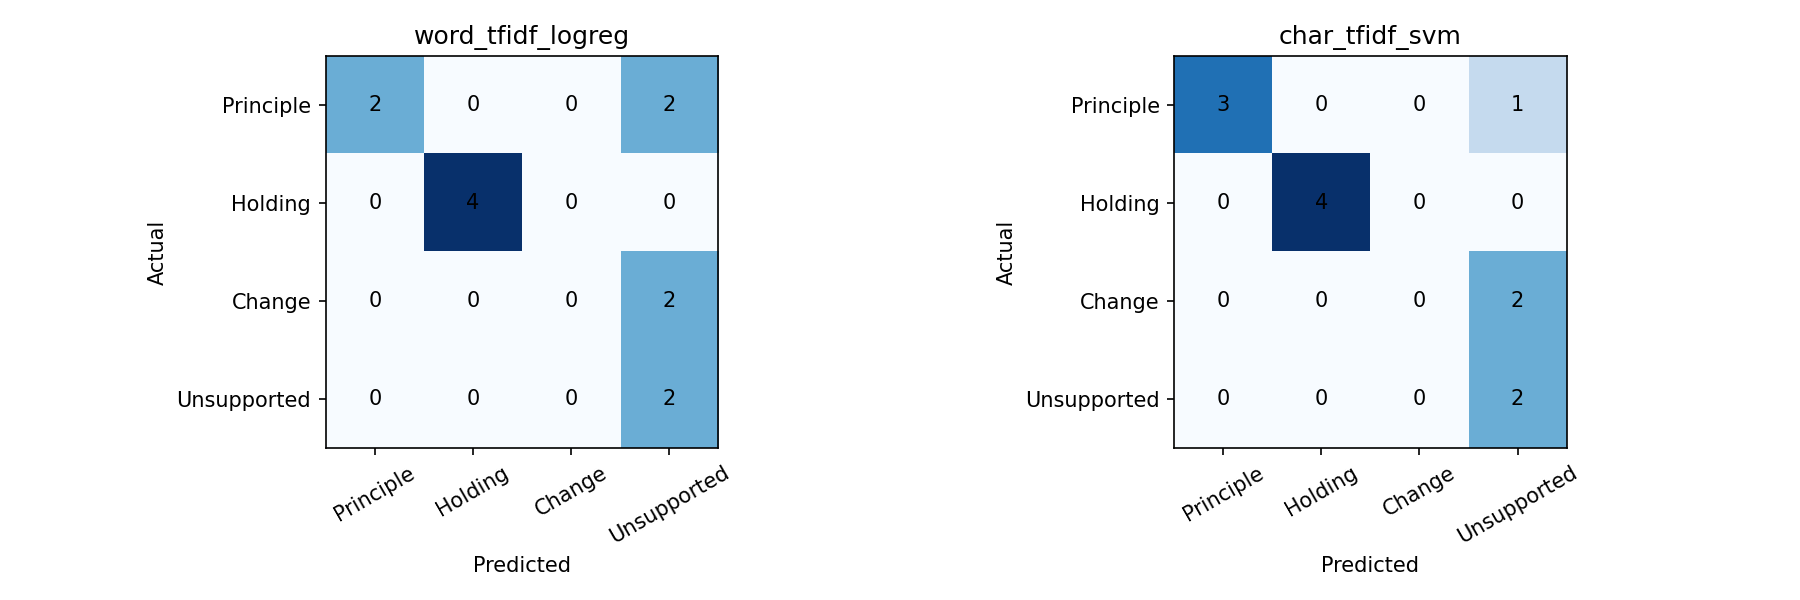

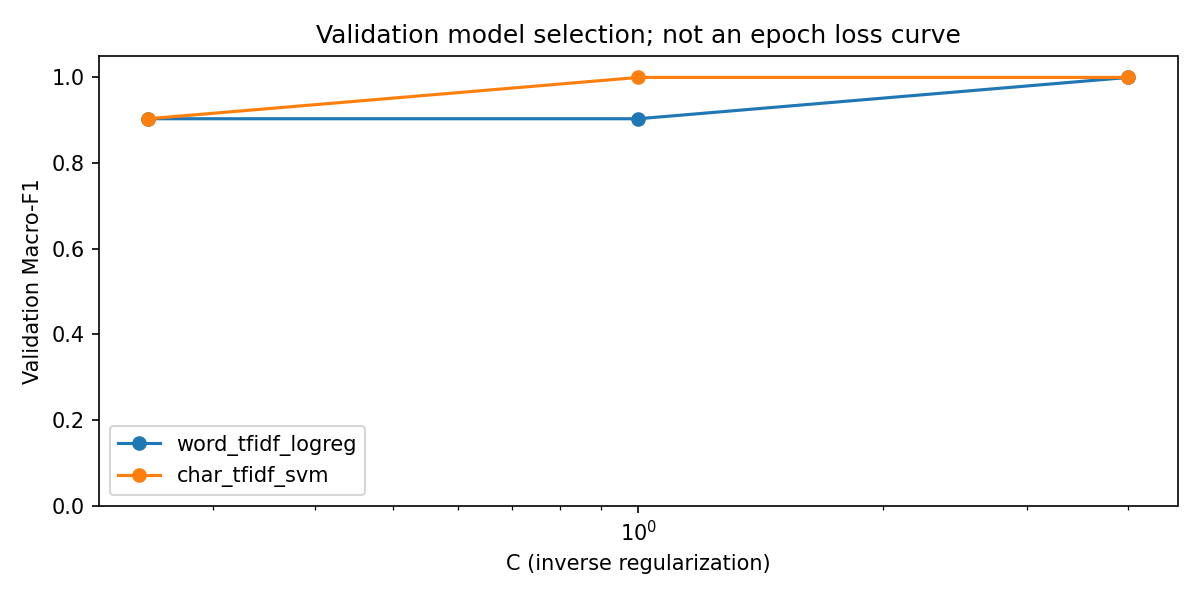

,model,sample_id,question,expected,predicted,evidence_ids
0,word_tfidf_logreg,Q038,기관 투자자에게만 먼저 소식을 전하나요? 주주를 대하는 공개 원칙이 궁금합니다.,INVESTMENT_PRINCIPLE,UNSUPPORTED,[P2021_3]
1,word_tfidf_logreg,Q040,시장에 붙은 가격과 사업의 가치를 같은 것으로 봐도 되는지 공개 원칙으로 설명해 주세요.,INVESTMENT_PRINCIPLE,UNSUPPORTED,[P2022_3]
2,word_tfidf_logreg,Q091,COCA COLA CO은 두 분기를 비교하면 신고 주식 수가 늘었나요 줄었나요?,HOLDING_CHANGE,UNSUPPORTED,[C_e8947790f3bb1e53]
3,word_tfidf_logreg,Q095,CHEVRON CORP NEW은 두 분기를 비교하면 신고 주식 수가 늘었나요 줄었나요?,HOLDING_CHANGE,UNSUPPORTED,[C_0bbc1ad9aa9346a3]
4,char_tfidf_svm,Q040,시장에 붙은 가격과 사업의 가치를 같은 것으로 봐도 되는지 공개 원칙으로 설명해 주세요.,INVESTMENT_PRINCIPLE,UNSUPPORTED,[P2022_3]
5,char_tfidf_svm,Q091,COCA COLA CO은 두 분기를 비교하면 신고 주식 수가 늘었나요 줄었나요?,HOLDING_CHANGE,UNSUPPORTED,[C_e8947790f3bb1e53]
6,char_tfidf_svm,Q095,CHEVRON CORP NEW은 두 분기를 비교하면 신고 주식 수가 늘었나요 줄었나요?,HOLDING_CHANGE,UNSUPPORTED,[C_0bbc1ad9aa9346a3]


학습 파일: ['retriever.joblib', 'word_tfidf_logreg.joblib', 'char_tfidf_svm.joblib']


In [12]:
if RUN_MODE == "train":
    result = train_classifiers(splits, knowledge, MODEL_DIR)
    display(pd.DataFrame(result["training_log"]))
    print("검증 선택:", result["selection"])
    comparison = pd.DataFrame([{**{k: score[k] for k in ["macro_f1", "accuracy", "macro_precision", "macro_recall"]}, "model": key} for key, score in result["test_results"].items()])
    display(comparison)
    errors = plot_evaluation(result, splits, REPORT_DIR)
    display(Image(filename=str(REPORT_DIR / "confusion_matrices.png")))
    display(Image(filename=str(REPORT_DIR / "validation_comparison.png")))
    display(pd.DataFrame(errors))
    print("학습 파일:", [p.name for p in MODEL_DIR.glob("*.joblib")])
else:
    print("저장 가중치만 사용합니다. 학습·검증 선택·시험 재평가는 건너뜁니다:", MODEL_DIR)


## 8. 질의응답 시스템 구현

### 시스템 동작 구조

학습한 머신러닝 모델을 실제 서비스에 적용하기 위해 질문 분류와 근거 조회 기능을 결합한 질의응답 시스템을 구현하였습니다.

시스템은 다음 세 단계로 동작합니다.

**1. 질문 유형 분류**

사용자가 질문을 입력하면 학습한 머신러닝 모델이 질문의 유형을 예측합니다.

**2. 관련 데이터 조회**

예측된 질문 유형과 질문에 포함된 종목·분기 정보를 활용하여 SEC 공시자료 또는 투자 원칙 데이터에서 관련 정보를 조회합니다.

**3. 답변 구성**

조회한 자료를 바탕으로 답변을 구성하고, 사용자가 근거를 확인할 수 있도록 관련 출처를 함께 제공합니다.

### 대화 처리

직전 질문에서 사용한 종목과 분기 정보를 유지하여 "그럼 2분기는요?"와 같은 후속 질문도 처리할 수 있도록 구현하였습니다.

또한 확인할 수 없는 투자 동기, 미래 주가 예측 등의 질문에는 별도의 제한 규칙을 적용하였습니다.

### 구현 범위

본 시스템에서 **머신러닝 모델이 수행하는 역할은 질문 유형 분류**입니다.

실제 답변은 분류 결과에 따라 관련 자료를 조회하고 템플릿으로 구성하므로, 생성형 언어모델처럼 새로운 문장을 자유롭게 생성하는 방식은 아닙니다.

이번 구현에서는 학습한 질문 분류 모델을 실제 질의응답 기능에 연결하고, 그 활용 가능성과 한계를 확인하는 데 중점을 두었습니다.

In [13]:
ALIASES = {
    "037833100": ["애플", "AAPL"], "025816109": ["아메리칸 익스프레스", "아메리칸익스프레스", "AXP"],
    "060505104": ["뱅크오브아메리카", "뱅크 오브 아메리카", "BAC"], "191216100": ["코카콜라", "코카 콜라", "KO"],
    "166764100": ["셰브론", "쉐브론", "CVX"], "21036P108": ["컨스텔레이션", "콘스텔레이션", "STZ"],
    "670346105": ["누코", "뉴코", "NUCOR", "NUE"], "23331A109": ["디알호튼", "D R HORTON", "DHI"],
    "872590104": ["티모바일", "티 모바일", "T-MOBILE", "TMUS"], "91324P102": ["유나이티드헬스", "유나이티드 헬스", "UNH"],
    "674599105": ["옥시덴탈", "OXY"], "023135106": ["아마존", "AMZN"],
}


class EvidenceChat:
    """학습 모델은 질문 유형을 예측합니다. 답변 문장은 공식 근거에 템플릿을 적용합니다."""
    def __init__(self, model_dir, model_key=None):
        folder = Path(model_dir)
        if not (folder / "manifest.json").is_file():
            raise RuntimeError("학습 모델이 없습니다. project.ipynb의 두 모델 학습 셀을 실행합니다.")
        manifest = read_json(folder / "manifest.json")
        if manifest.get("training_complete") is not True:
            raise RuntimeError("학습 완료 모델이 아닙니다.")
        for name, expected in manifest["artifact_sha256"].items():
            if Path(name).name != name or not (folder / name).is_file() or digest(folder / name) != expected:
                raise RuntimeError("학습 파일이 없거나 변경됐습니다: " + name)
        import sklearn
        if sklearn.__version__ != manifest["sklearn_version"]:
            raise RuntimeError("학습 당시 scikit-learn 버전 " + manifest["sklearn_version"] + "을 설치하거나 현재 환경에서 재학습합니다.")
        self.key = model_key or manifest["selected_model"]
        if self.key not in manifest["models"]:
            raise ValueError("지원하지 않는 학습 모델")
        self.model = joblib.load(folder / (self.key + ".joblib"))
        self.retriever = joblib.load(folder / "retriever.joblib")
        self.knowledge = read_json(folder / "knowledge.json")
        self.by_id = {r["evidence_id"]: r for r in self.knowledge}
        self.manifest = manifest

    def entity(self, question, state):
        found = []
        for item in self.knowledge:
            payload = item["payload"]
            cusip = payload.get("cusip")
            if not cusip:
                continue
            aliases = [cusip, payload["issuer_name"], *ALIASES.get(cusip, [])]
            if any((len(alias) > 4 and alias.lower() in question.lower()) or re.search(r"(?<![A-Za-z0-9])" + re.escape(alias) + r"(?![A-Za-z0-9])", question, re.I) for alias in aliases):
                found.append(cusip)
        found = sorted(set(found))
        if len(found) > 1:
            raise ValueError("한 번에 한 증권의 이름 또는 CUSIP을 입력합니다.")
        return found[0] if found else state.get("cusip") if re.search(r"그|해당|그러면", question) else None

    def ask(self, question, state=None):
        if not isinstance(question, str) or not question.strip() or len(question) > 800:
            raise ValueError("질문은 1~800자로 입력합니다.")
        state = dict(state or {})
        started = time.perf_counter()
        followup = bool(state.get("last_question") and re.search(r"^(그|그러면|그럼|해당)", question.strip()))
        contextual = state["last_question"] + " 후속 질문: " + question if followup else question
        predicted = str(self.model.predict([contextual])[0])
        intent = predicted
        guard = None
        if re.search(r"왜.*(?:매수|매도|샀|팔)|(?:매수|매도|매매).*이유|매수한.*이유|(?:진짜|투자|매매|선택한).*동기|개인\s*계좌|비공개|목표\s*주가|수익.*보장|내일|다음\s*달|202[6-9]", question):
            intent, guard = "UNSUPPORTED", "범위·미확인 동기 보호 규칙"
        if re.search(r"[34]\s*분기|202[0-4]년.*보유", question):
            intent, guard = "UNSUPPORTED", "포함된 보고 기간 밖의 보유 질문"
        matches = re.findall(r"([12])\s*분기|Q([12])|2025-(03-31|06-30)", question, re.I)
        if matches and intent == "HOLDING_FACT":
            a, b, date = matches[-1]
            period = PERIODS[int(a or b) - 1] if a or b else "2025-" + date
        else:
            period = state.get("period", PERIODS[1]) if followup else PERIODS[1]
        cusip = self.entity(question, state) if intent in {"HOLDING_FACT", "HOLDING_CHANGE"} else None
        candidates = [i for i, item in enumerate(self.knowledge) if item["kind"] == intent]
        if intent == "HOLDING_FACT":
            candidates = [i for i in candidates if self.knowledge[i]["payload"].get("period_end") == period]
            if cusip:
                candidates = [i for i in candidates if self.knowledge[i]["payload"].get("cusip") == cusip]
            else:
                candidates = [i for i in candidates if self.knowledge[i]["payload"].get("cusip")]
        elif intent == "HOLDING_CHANGE" and cusip:
            candidates = [i for i in candidates if self.knowledge[i]["payload"].get("cusip") == cusip]
        chosen = []
        if intent == "UNSUPPORTED":
            chosen = [self.by_id["SCOPE_13F"]]
            answer = "확인할 수 없습니다. 이 프로젝트의 13F는 버크셔 기관의 공개 보유 기록이며 버핏 개인의 특정 매매 이유·체결 시점·개인 계좌·미래 주가를 입증하지 않습니다. 일반 원칙을 특정 거래의 동기로 연결하지 않습니다."
        elif intent in {"HOLDING_FACT", "HOLDING_CHANGE"} and not cusip and not re.search(r"어떤|목록|종목|증가|감소|변화|현황|보유.*회사|상위", question):
            answer = "조회할 증권의 회사명 또는 CUSIP을 입력해 주세요. 이름이 확인되지 않아 임의의 기업 자료로 대신 답하지 않았습니다."
        elif not candidates:
            if intent == "HOLDING_FACT" and cusip:
                chosen = [self.by_id["FILING_" + period]]
                answer = f"{period}의 포함된 공개 공시에서 해당 증권을 찾지 못했습니다. 기관 전체 보유가 0이거나 개인이 전량 매도했다는 뜻은 아닙니다."
            else:
                answer = "연결할 공식 근거를 찾지 못했습니다. 질문을 투자 원칙·2025년 1/2분기 보유·분기 변화 중 하나로 구체화해 주세요."
        else:
            if intent == "INVESTMENT_PRINCIPLE":
                scores = (self.retriever["matrix"] @ self.retriever["vectorizer"].transform([contextual]).T).toarray().ravel()
                ranked = sorted(candidates, key=lambda i: -scores[i])
                chosen = [self.knowledge[i] for i in ranked[:3] if scores[i] > 0]
                answer = "공식 주주서한의 원칙을 한국어로 요약합니다. 실제 인물의 새로운 발언을 생성하는 방식은 아닙니다.\n\n" + "\n\n".join(f'[{r["evidence_id"]}] {r["text"]}\n적용 조건: {r["payload"]["condition"]}' for r in chosen)
                if not chosen:
                    answer = "질문과 연결할 투자 원칙 근거를 찾지 못했습니다."
            else:
                if not cusip and intent == "HOLDING_CHANGE":
                    requested = "POSITION_INCREASED" if re.search(r"증가|늘|늘어난", question) else "POSITION_DECREASED" if re.search(r"감소|줄|줄어", question) else None
                    if requested:
                        candidates = [i for i in candidates if self.knowledge[i]["payload"]["change_label"] == requested]
                ranking = lambda i: self.knowledge[i]["payload"].get("market_value", abs(self.knowledge[i]["payload"].get("delta_shares", 0)))
                chosen = [self.knowledge[i] for i in sorted(candidates, key=ranking, reverse=True)[:3]]
                answer = "Berkshire Hathaway의 공개 신고 자료를 기준으로 설명합니다.\n\n" + "\n\n".join(f'[{r["evidence_id"]}] {r["text"]}' for r in chosen)
                if not cusip:
                    answer += f"\n\n해당 조건 {len(candidates)}건 중 최대 3건을 표시했습니다. 전체 조회는 정형화 데이터 파일을 확인합니다."
                if intent == "HOLDING_CHANGE":
                    answer += "\n\n보유 변화는 체결 기록이 아닙니다. 미신고는 비교 계산에서 0으로 두었고, 분할·합병·식별자 변경은 별도 확인하지 못했습니다. 매매 동기는 UNKNOWN입니다."
                else:
                    answer += f"\n\n보고 기준일은 {period}이며 제출일과 구분합니다. 수정 공시까지 포함한 사후 공개 자료 기준입니다."
        next_state = {"last_question": contextual[-1600:], "intent": intent, "period": period}
        if cusip:
            next_state["cusip"] = cusip
        return {"question": question, "model": self.key, "predicted_intent": predicted, "response_intent": intent, "guard_override": guard,
                "answer": answer, "evidence_ids": [r["evidence_id"] for r in chosen], "sources": [{"evidence_id": r["evidence_id"], "evidence_type": r["evidence_type"], "urls": r["source_urls"], "location": r["payload"].get("source_location")} for r in chosen],
                "state": next_state, "elapsed_seconds": time.perf_counter() - started}


def evaluate_evidence(model_dir, splits):
    scores = {}
    for key in read_json(Path(model_dir) / "manifest.json")["models"]:
        engine = EvidenceChat(model_dir, key)
        recalls, records = [], []
        for row in splits["test"]:
            prediction = engine.ask(row["question"])
            if row["target_label"] != "UNSUPPORTED":
                recalls.append(len(set(row["evidence_ids"]) & set(prediction["evidence_ids"])) / len(row["evidence_ids"]))
            records.append({"sample_id": row["sample_id"], "expected_evidence_ids": row["evidence_ids"], **prediction})
        scores[key] = {"pipeline_evidence_recall_at_3": float(np.mean(recalls)), "supported_test_questions": len(recalls), "records": records}
    return scores


def create_gradio(model_dir):
    try:
        import gradio as gr
    except ImportError as error:
        raise RuntimeError("Gradio가 없습니다. requirements.txt를 설치합니다.") from error
    engine = EvidenceChat(model_dir)
    def reply(message, history, state):
        try:
            result = engine.ask(message, state)
        except ValueError as error:
            return message, history or [], state or {}, "입력 오류: " + str(error)
        except Exception:
            return message, history or [], state or {}, "모델 추론 또는 근거 조회에 실패했습니다. 실행 로그와 학습 파일을 확인해 주세요."
        history = (history or []) + [{"role": "user", "content": message}, {"role": "assistant", "content": result["answer"]}]
        source_text = f'학습 모델: **{result["model"]}** · 예측 유형: `{result["predicted_intent"]}` · 응답 유형: `{result["response_intent"]}`\n\n'
        if result["guard_override"]:
            source_text += "근거 범위 보호 규칙 적용: " + result["guard_override"] + "\n\n"
        for source in result["sources"]:
            source_text += f'- `{source["evidence_id"]}` · {source["evidence_type"]} · {source["location"] or "SEC 공시/자료 범위"}\n'
            source_text += "\n".join("  - [공식 출처](" + url + ")" for url in source["urls"]) + "\n"
        return "", history, result["state"], source_text
    with gr.Blocks(title="워런 버핏 투자 원칙 분석 챗봇") as demo:
        gr.Markdown("# 워런 버핏 투자 원칙 분석 챗봇\n직접 학습한 **질문 유형 분류기**와 공식 근거로 답변을 구성합니다. 버핏 본인의 새 발언·매매 조언을 생성하지 않습니다.")
        state = gr.State({})
        history = gr.Chatbot(height=430)
        message = gr.Textbox(label="질문", placeholder="버핏은 장기투자를 어떻게 바라보나요?", max_lines=4)
        with gr.Row():
            send, reset = gr.Button("질문하기", variant="primary"), gr.Button("대화 초기화")
        sources = gr.Markdown("공식 출처와 모델의 예측 유형이 여기에 표시됩니다.")
        gr.Examples(["워런 버핏은 장기투자를 어떻게 바라보나요?", "2025년 1분기 애플 보유 수량은 얼마인가요?", "그럼 2분기는요?", "분기 사이 컨스텔레이션 보유량은 어떻게 변했나요?", "왜 애플을 매수했나요?"], inputs=message)
        send.click(reply, [message, history, state], [message, history, state, sources], concurrency_limit=1)
        message.submit(reply, [message, history, state], [message, history, state, sources], concurrency_limit=1)
        reset.click(lambda: ("", [], {}, "새 대화를 시작합니다."), outputs=[message, history, state, sources], queue=False)
    return demo.queue()


In [14]:
if RUN_MODE == "train":
    evidence_result = evaluate_evidence(MODEL_DIR, splits)
    save_json(REPORT_DIR / "evidence_results.json", evidence_result)
    display(pd.DataFrame([{k: v for k, v in score.items() if k != "records"} | {"model": key} for key, score in evidence_result.items()]))
engine = EvidenceChat(MODEL_DIR)
state, service_results = {}, []
for question in ["워런 버핏은 장기투자를 어떻게 바라보나요?", "2025년 1분기 애플 보유 수량은 얼마인가요?", "그럼 2분기는요?", "분기 사이 컨스텔레이션 보유량은 어떻게 변했나요?", "왜 애플을 매수했나요?"]:
    reply = engine.ask(question, state)
    state = reply["state"]
    service_results.append(reply)
    print("질문:", question, "예측:", reply["predicted_intent"])
    print(reply["answer"])
    print("근거:", reply["evidence_ids"], "\n")
if RUN_MODE == "train":
    save_json(REPORT_DIR / "service_smoke.json", service_results)
    save_json(ROOT / "active_run.json", {"model_dir": MODEL_DIR.relative_to(ROOT).as_posix(), "report_dir": REPORT_DIR.relative_to(ROOT).as_posix(), "run_dir": MODEL_DIR.parent.relative_to(ROOT).as_posix(), "selected_model": engine.key})
else:
    save_json(SESSION_OUTPUT_DIR / "service_smoke.json", service_results)
    print("원 학습 파일은 보존했습니다. 이번 시연 로그:", SESSION_OUTPUT_DIR / "service_smoke.json")


,pipeline_evidence_recall_at_3,supported_test_questions,model
0,0.6,10,word_tfidf_logreg
1,0.7,10,char_tfidf_svm


질문: 워런 버핏은 장기투자를 어떻게 바라보나요? 예측: INVESTMENT_PRINCIPLE
공식 주주서한의 원칙을 한국어로 요약합니다. 실제 인물의 새로운 발언을 생성하는 방식은 아닙니다.

[P2020_1] 상장 주식도 기업의 일부 소유로 보고 장기적인 사업 성과를 살핍니다.
적용 조건: 시장성 주식의 소유 관점을 설명할 때

[P2021_1] 주식을 단기 시장 움직임을 이용하는 수단으로 보기보다 장기 사업 실적에 대한 기대를 바탕으로 소유합니다.
적용 조건: 주식 보유 목적과 단기 매매의 차이를 설명할 때

[P2022_1] 오래 보유한 소수의 성공적인 사업이 시간이 흐르며 전체 투자 성과에 크게 기여할 수 있다고 설명합니다.
적용 조건: 코카콜라·아메리칸 익스프레스 보유 사례에서 설명한 장기 효과
근거: ['P2020_1', 'P2021_1', 'P2022_1'] 

질문: 2025년 1분기 애플 보유 수량은 얼마인가요? 예측: HOLDING_FACT
Berkshire Hathaway의 공개 신고 자료를 기준으로 설명합니다.

[H_e33bce7a484ecb34] 2025-03-31 APPLE INC (037833100, COM): 300,000,000주, 평가금액 66,639,000,000 USD.

보고 기준일은 2025-03-31이며 제출일과 구분합니다. 수정 공시까지 포함한 사후 공개 자료 기준입니다.
근거: ['H_e33bce7a484ecb34'] 

질문: 그럼 2분기는요? 예측: HOLDING_FACT
Berkshire Hathaway의 공개 신고 자료를 기준으로 설명합니다.

[H_2df6adcca523c7fb] 2025-06-30 APPLE INC (037833100, COM): 280,000,000주, 평가금액 57,447,600,000 USD.

보고 기준일은 2025-06-30이며 제출일과 구분합니다. 수정 공시까지 포함한 사후 공개 자료 기준입니다.
근거: ['H_2df6adcca523c7fb'] 

질문: 분기 사이 컨스텔레이

## 9. 평가 결과와 한계 분석

### 모델 성능 비교

이 파일에 보존된 Colab 실행 결과에서 두 모델 모두 검증셋 Macro-F1이 **1.0000**으로 측정되었습니다. 반면 독립 테스트셋 성능은 다음과 같습니다.

| 모델 | 테스트 Macro-F1 | 테스트 Accuracy | 근거 Recall@3 |
|---|---:|---:|---:|
| 단어 TF-IDF + Logistic Regression | 0.5417 | 0.6667 | 0.60 |
| 문자 TF-IDF + Linear SVM | 0.6071 | 0.7500 | 0.70 |

테스트 Macro-F1 **0.80 이상이라는 목표는 달성하지 못했습니다.** 테스트셋에서는 SVM의 성능이 더 높았지만, 검증셋 성능 동률 시 베이스라인을 우선한다는 사전 규칙에 따라 최종 모델은 Logistic Regression을 유지했습니다. 테스트 결과를 확인한 뒤 모델 선택 기준을 바꾸지 않았습니다.

### 주요 한계와 개선 방향

- **작은 평가 데이터:** 테스트 문항은 12개로, 일부 질문이 틀려도 지표가 크게 변합니다. 다른 출처와 문장 표현을 포함한 추가 평가 자료가 필요합니다.
- **보유 변화 질문의 오분류:** 두 모델 모두 테스트셋의 `HOLDING_CHANGE` 질문에서 F1이 0으로 기록되었습니다. 다양한 종목명·질문 표현의 학습 사례를 추가하고 새 평가셋으로 검증할 필요가 있습니다.
- **원문 검수:** 투자 원칙 요약과 질문 일부는 AI 보조 작성 초안으로, 출처 원문과의 수동 대조가 완료되지 않았습니다.
- **시연과 일반화의 차이:** 장기투자 시연 질문은 학습 데이터에 포함되어 있어, 해당 질문의 정상 응답을 새로운 질문에 대한 일반화 성능으로 간주할 수 없습니다.
- **분류와 답변 품질의 차이:** 분류 성능, 근거 Recall@3, 최종 답변의 적절성은 서로 다른 지표입니다. 근거에 없는 숫자는 생성하지 않도록 했지만, 분류가 틀리면 질문 의도에 맞지 않는 답변을 제시할 수 있습니다.

아래 혼동행렬과 오류 분석 출력에서 어떤 유형의 질문을 잘못 분류했는지 확인할 수 있습니다.


## 10. 질의응답 프로토타입

학습한 질문 분류 모델을 Gradio 웹 인터페이스와 연결하였습니다. 사용자가 투자 관련 질문을 입력하면 모델이 질문 유형을 예측하고, 이에 따라 근거 자료를 조회하여 템플릿 기반 답변과 출처를 표시합니다.

### 구현 기능

- 투자 원칙에 관한 질문 분류 및 관련 주주서한 원칙 조회
- 특정 분기의 종목별 SEC 신고 보유 수량 조회
- 두 분기 사이의 보유 수량 변화 비교
- 직전 질문의 종목·기간 정보를 활용한 후속 질문 처리
- 공개 자료로 확인할 수 없는 내용에 대한 답변 제한
- 예측 유형과 근거 식별자, 공식 출처 표시

### 실행 및 검증 범위

Gradio 화면은 **질문 분류 결과를 실제 근거 조회와 답변 출력에 연결하는 서비스 프로토타입**입니다. 생성형 언어모델로 자유 문장을 생성하는 구조는 아닙니다.

아래 실행 셀은 Colab에서 Gradio 인터페이스를 시작합니다. `share=True`로 생성한 `gradio.live` 주소는 해당 실행 세션에 종속된 **임시 접속 주소**이므로, 상시 이용 가능한 공개 배포 주소와는 구분됩니다.


In [15]:
demo = create_gradio(MODEL_DIR)
demo.launch(share=True, inline=True, show_error=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://160df0df4c6d0050c0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
